# Práctica de Basic Regression

## 1. Carga de librerías necesarias y del dataset

### 1.1. Importación de librerías

- `pandas`: manipulación de datos.

- `numpy`: operaciones numéricas.

- `matplotlib` y `seaborn`: visualización (seaborn para gráficos estadísticos más limpios).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

### 2.2. Carga del dataset

In [2]:
data_gdp = pd.read_csv(
    "data/countries_gdp.csv",
    sep=";",
    decimal=",",
    engine="python",
)
data_gdp.head()

,Unnamed: 0,Country,Region,Population,Area,Pop.Density,Coastline,Net.migration,Infant.mortality,GDP,...,Phones,Arable,Crops,Other,Climate,Birthrate,Deathrate,Agriculture,Industry,Service
0,0,Afghanistan,ASIA (EX. NEAR EAST),31056997,647500,48.0,0.00,23.06,163.07,700.0,...,3.2,12.13,0.22,87.65,1.0,46.60,20.34,0.380,0.240,0.380
1,1,Albania,EASTERN EUROPE,3581655,28748,124.6,1.26,-4.93,21.52,4500.0,...,71.2,21.09,4.42,74.49,3.0,15.11,5.22,0.232,0.188,0.579
2,2,Algeria,NORTHERN AFRICA,32930091,2381740,13.8,0.04,-0.39,31.00,6000.0,...,78.1,3.22,0.25,96.53,1.0,17.14,4.61,0.101,0.600,0.298
3,3,American Samoa,OCEANIA,57794,199,290.4,58.29,-20.71,9.27,8000.0,...,259.5,10.00,15.00,75.00,2.0,22.46,3.27,NaN,NaN,NaN
4,4,Andorra,WESTERN EUROPE,71201,468,152.1,0.00,6.60,4.05,19000.0,...,497.2,2.22,0.00,97.78,3.0,8.71,6.25,NaN,NaN,NaN


In [3]:
data_gdp = data_gdp.drop(columns=["Unnamed: 0"])
data_gdp.columns


Index(['Country', 'Region', 'Population', 'Area', 'Pop.Density', 'Coastline',
       'Net.migration', 'Infant.mortality', 'GDP', 'Literacy', 'Phones',
       'Arable', 'Crops', 'Other', 'Climate', 'Birthrate', 'Deathrate',
       'Agriculture', 'Industry', 'Service'],
      dtype='object')

Se elimina la columna Unnamed: 0, ya que corresponde a un índice generado automáticamente durante la exportación del archivo y no contiene información relevante para el análisis.

---

## A. (2) Realiza un análisis descriptivo completo de los datos.

### A.1. Exploración inicial

#### Objetivo

El objetivo de esta sección es realizar una primera exploración del conjunto de datos con el fin de comprender su estructura, identificar el tipo de variables disponibles y detectar posibles problemas de calidad del dato. En esta fase no se realiza ningún tipo de limpieza ni transformación.

---

#### Dimensiones del conjunto de datos:

In [4]:
data_gdp.shape

(227, 20)

El conjunto de datos contiene 227 observaciones (países) y 20 variables.

---

#### Estructura y tipos de datos

In [5]:
data_gdp.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 227 entries, 0 to 226
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Country           227 non-null    object 
 1   Region            227 non-null    object 
 2   Population        227 non-null    int64  
 3   Area              227 non-null    int64  
 4   Pop.Density       227 non-null    float64
 5   Coastline         227 non-null    float64
 6   Net.migration     224 non-null    float64
 7   Infant.mortality  224 non-null    float64
 8   GDP               226 non-null    float64
 9   Literacy          209 non-null    float64
 10  Phones            223 non-null    float64
 11  Arable            225 non-null    float64
 12  Crops             225 non-null    float64
 13  Other             225 non-null    float64
 14  Climate           205 non-null    float64
 15  Birthrate         224 non-null    float64
 16  Deathrate         223 non-null    float64
 1

El conjunto de datos presenta una tipología de variables coherente con la descripción proporcionada en el enunciado de la práctica. Las variables `Country` y `Region` aparecen correctamente identificadas como variables categóricas (object), actuando la primera como identificador del país y la segunda como variable de agrupación geográfica.

El resto de variables son de tipo numérico (int64 y float64), lo cual es consistente con su naturaleza según el enunciado: variables demográficas como `Population` y `Area` se representan como enteros, mientras que indicadores socioeconómicos, tasas, porcentajes y ratios (por ejemplo, `Pop.Density`, `GDP`, `Literacy`, `Birthrate` o la composición sectorial) se almacenan como valores continuos. En conjunto, los tipos de datos asignados resultan adecuados para el análisis estadístico y de regresión planteado en la práctica.

---

#### Estadísticos descriptivos iniciales

In [6]:
data_gdp.describe().T

,count,mean,std,min,25%,50%,75%,max
Population,227.0,2.874028e+07,1.178913e+08,7026.000,437624.00000,4786994.000,1.749777e+07,1.313974e+09
Area,227.0,5.982270e+05,1.790282e+06,2.000,4647.50000,86600.000,4.418110e+05,1.707520e+07
Pop.Density,227.0,3.790471e+02,1.660186e+03,0.000,29.15000,78.800,1.901500e+02,1.627150e+04
Coastline,227.0,2.116533e+01,7.228686e+01,0.000,0.10000,0.730,1.034500e+01,8.706600e+02
Net.migration,224.0,3.812500e-02,4.889269e+00,-20.990,-0.92750,0.000,9.975000e-01,2.306000e+01
Infant.mortality,224.0,3.550696e+01,3.538990e+01,2.290,8.15000,21.000,5.570500e+01,1.911900e+02
GDP,226.0,9.689823e+03,1.004914e+04,500.000,1900.00000,5550.000,1.570000e+04,5.510000e+04
Literacy,209.0,8.283828e+01,1.972217e+01,17.600,70.60000,92.500,9.800000e+01,1.000000e+02
Phones,223.0,2.360614e+02,2.279918e+02,0.200,37.80000,176.200,3.896500e+02,1.035600e+03
Arable,225.0,1.379711e+01,1.304040e+01,0.000,3.22000,10.420,2.000000e+01,6.211000e+01


Los estadísticos descriptivos muestran una alta heterogeneidad en la escala y dispersión de las variables numéricas del conjunto de datos. Variables como `Population`, `Area` y `GDP` presentan rangos muy amplios y desviaciones estándar elevadas en relación con sus medias, lo que indica una fuerte dispersión y la posible presencia de distribuciones asimétricas.

Por el contrario, variables expresadas como tasas o porcentajes (por ejemplo, `Literacy`, `Birthrate`, `Deathrate` o la composición sectorial `Agriculture`, `Industry` y `Service`) muestran rangos más acotados y valores centrales más representativos. En conjunto, estos resultados reflejan la coexistencia de variables en distintas escalas y con diferentes patrones de distribución, algo habitual en datos socioeconómicos a nivel país y relevante para el análisis posterior.

---

#### Comprobaciones básicas de calidad del dato

##### Valores nulos por variable

In [7]:
data_gdp.isna().sum().sort_values(ascending=False)

Climate             22
Literacy            18
Industry            16
Agriculture         15
Service             15
Phones               4
Deathrate            4
Infant.mortality     3
Net.migration        3
Birthrate            3
Crops                2
Arable               2
Other                2
GDP                  1
Region               0
Country              0
Area                 0
Population           0
Coastline            0
Pop.Density          0
dtype: int64


El conjunto de datos presenta **valores nulos en varias variables**, aunque ninguna de ellas muestra una ausencia masiva de información. Las variables `Country`, `Region`, `Population`, `Area`, `Pop.Density` y `Coastline` no presentan valores perdidos, lo que indica una cobertura completa para los identificadores y las variables geográficas básicas.

Por otro lado, se observa la presencia de valores nulos en algunos indicadores socioeconómicos y demográficos. Destacan especialmente `Climate`, `Literacy` y las variables de composición sectorial (`Agriculture`, `Industry` y `Service`), que concentran un mayor número de observaciones incompletas. También se detecta un número reducido de valores ausentes en la variable objetivo `GDP`.

Este patrón refleja una **disponibilidad desigual de información entre variables** que deberá tenerse en cuenta en el tratamiento específico de valores perdidos en secciones posteriores del análisis.

---


##### Duplicados

In [8]:
data_gdp.duplicated().sum()

np.int64(0)


El análisis de registros duplicados indica que **no existen observaciones duplicadas** en el conjunto de datos. Cada fila corresponde a un país distinto, lo que garantiza que no se produce una sobre-representación de ninguna observación y que los análisis descriptivos y posteriores modelos de regresión no se verán afectados por duplicidades en los datos.

---


### A.2 Análisis univariante de las variables

#### Objetivo del apartado

El objetivo de este apartado es analizar **de forma individual** cada una de las variables del conjunto de datos con el fin de comprender su distribución, escala y variabilidad. Este análisis permite identificar patrones generales, posibles asimetrías y la presencia de valores extremos, proporcionando una base sólida para los análisis posteriores.  
Para ello, se utilizan representaciones gráficas adecuadas en función de la **naturaleza de cada variable**, evitando el uso indiscriminado de gráficos y priorizando aquellos que aportan mayor información descriptiva.

---


#### A.2.1. Clasificación detallada de las variables según su naturaleza

A continuación, se clasifican **una a una** las variables del conjunto de datos en función de su naturaleza y significado, justificando su inclusión en cada categoría.

---

##### Variables continuas

Estas variables representan magnitudes medidas en una escala continua, por lo que resulta adecuado analizar su distribución mediante histogramas y boxplots.

- **GDP**: variable objetivo que mide el Producto Interior Bruto per cápita; es una magnitud económica continua.
- **Pop.Density**: densidad de población; variable continua que puede tomar una amplia gama de valores.
- **Coastline**: ratio de costa; medida continua que expresa una relación geográfica.
- **Net.migration**: migración neta; variable continua que puede tomar valores positivos y negativos.
- **Infant.mortality**: tasa de mortalidad infantil; indicador continuo expresado como tasa.
- **Literacy**: tasa de alfabetización (%); variable continua acotada entre 0 y 100.
- **Phones**: número de teléfonos por cada 1000 habitantes; variable continua.
- **Birthrate**: tasa de natalidad; variable continua.
- **Deathrate**: tasa de mortalidad; variable continua.
- **Agriculture**: porcentaje del PIB procedente del sector agrícola; variable continua.
- **Industry**: porcentaje del PIB procedente del sector industrial; variable continua.
- **Service**: porcentaje del PIB procedente del sector servicios; variable continua.
- **Arable**: porcentaje de tierra arable; variable continua.
- **Crops**: porcentaje de tierra dedicada a cultivos; variable continua.
- **Other**: porcentaje de otros usos del suelo; variable continua.

---

##### Variables discretas o numéricas no continuas

Estas variables, aunque numéricas, toman valores discretos o actúan como códigos, por lo que no resulta adecuado analizarlas mediante histogramas continuos.

- **Population**: número total de habitantes; aunque es numérica, toma valores enteros y presenta una escala extremadamente amplia, lo que aconseja un tratamiento diferenciado.
- **Area**: superficie del país; variable entera con gran dispersión y naturaleza discreta en el conjunto de datos.

---

##### Variables categóricas

Estas variables identifican categorías o entidades y no poseen una interpretación numérica directa.

- **Climate**: variable codificada que representa distintos tipos de clima; sus valores numéricos actúan como categorías ordenadas.
- **Country**: identificador del país; variable puramente nominal sin significado cuantitativo.
- **Region**: región geográfica a la que pertenece cada país; variable categórica utilizada para agrupar observaciones.

---

En el análisis univariante, las variables continuas clásicas se analizan en su escala original, ya que esta refleja adecuadamente la variabilidad del fenómeno. En cambio, para variables de conteo o magnitudes con escalas extremadamente amplias, se recurre a cambios de escala con fines exclusivamente descriptivos, con el objetivo de facilitar la visualización sin alterar la naturaleza de los datos.

---


#### A.2.2. Análisis gráfico de las variables continuas

In [9]:
def plot_distribucion_series(x, titulo="Distribución", bins=30):
    """Pinta Boxplot (arriba) + Histograma (abajo) para una Serie/array."""
    x = pd.Series(x).dropna()

    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, sharex=True,
        gridspec_kw={"height_ratios": (.15, .85)},
        figsize=(10, 6)
    )

    # 1) Boxplot (arriba)
    sns.boxplot(x=x, ax=ax_box, color="skyblue")
    ax_box.set(xlabel="")
    ax_box.set_title(titulo, fontweight="bold")

    # 2) Histograma (abajo)
    sns.histplot(x=x, ax=ax_hist, kde=True, color="dodgerblue", bins=bins)

    # Líneas de referencia: media y mediana
    ax_hist.axvline(x.mean(), color="red", linestyle="--", label=f"Media: {x.mean():.2f}")
    ax_hist.axvline(x.median(), color="green", linestyle="-", label=f"Mediana: {x.median():.2f}")
    ax_hist.legend()

    plt.tight_layout()
    plt.show()

##### A.2.2.1. Análisis univariante de la variable `GDP` (per cápita)

In [10]:
# Para el análisis gráfico se excluyen temporalmente los valores nulos de GDP,
# con el único objetivo de evitar problemas de visualización en los gráficos.
# En esta fase no se realiza ningún tratamiento ni imputación de los datos.

gdp_clean = data_gdp["GDP"].dropna()


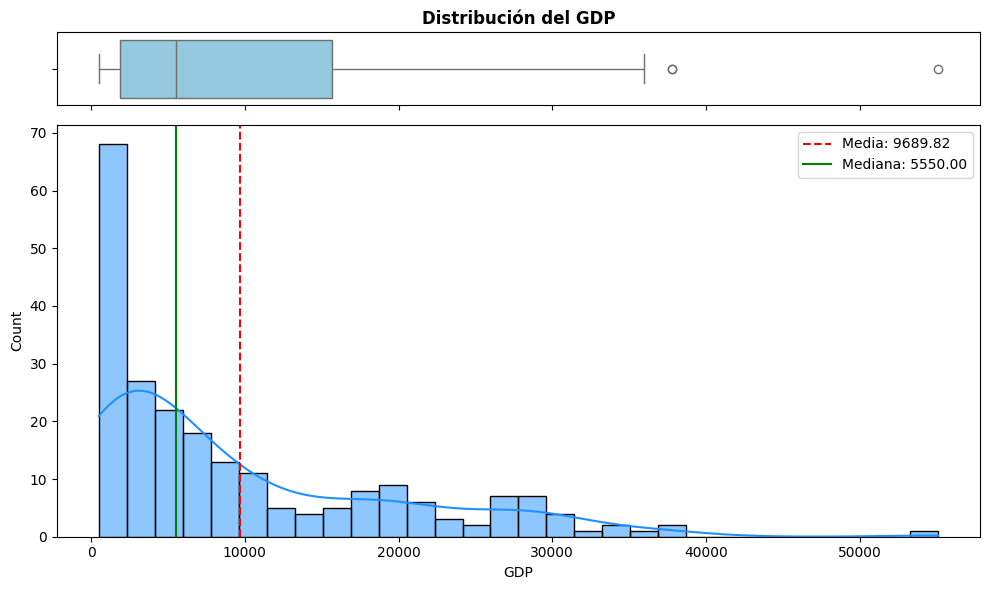

In [11]:
# Llamada para GDP
plot_distribucion_series(gdp_clean, titulo="Distribución del GDP", bins=30)

In [12]:
data_gdp["GDP"].describe()


count      226.000000
mean      9689.823009
std      10049.138513
min        500.000000
25%       1900.000000
50%       5550.000000
75%      15700.000000
max      55100.000000
Name: GDP, dtype: float64

**Conclusiones (variable GDP)**

La distribución observada en el histograma muestra una clara **asimetría positiva**, con una alta concentración de países en niveles bajos de PIB per cápita y una cola larga hacia valores elevados, lo que concuerda con la diferencia apreciable entre la media (≈ 9 690) y la mediana (≈ 5 550).

El boxplot refuerza esta interpretación, situando la mediana claramente desplazada hacia el primer cuartil y mostrando una dispersión considerable en el rango intercuartílico (Q1 ≈ 1 900, Q3 ≈ 15 700). Asimismo, se identifican **valores extremos elevados**, coherentes con el valor máximo observado (55 100), que representan países con niveles de renta per cápita muy superiores al resto.

Dada la marcada asimetría de la variable objetivo, en secciones posteriores se valorará la conveniencia de aplicar transformaciones sobre `GDP`.

En conjunto, tanto los gráficos como los estadísticos descriptivos reflejan una **distribución muy heterogénea y no simétrica** del PIB per cápita entre países, relevante para el análisis posterior.

---

##### A.2.2.2. Análisis univariante de la variable `Pop.Density`

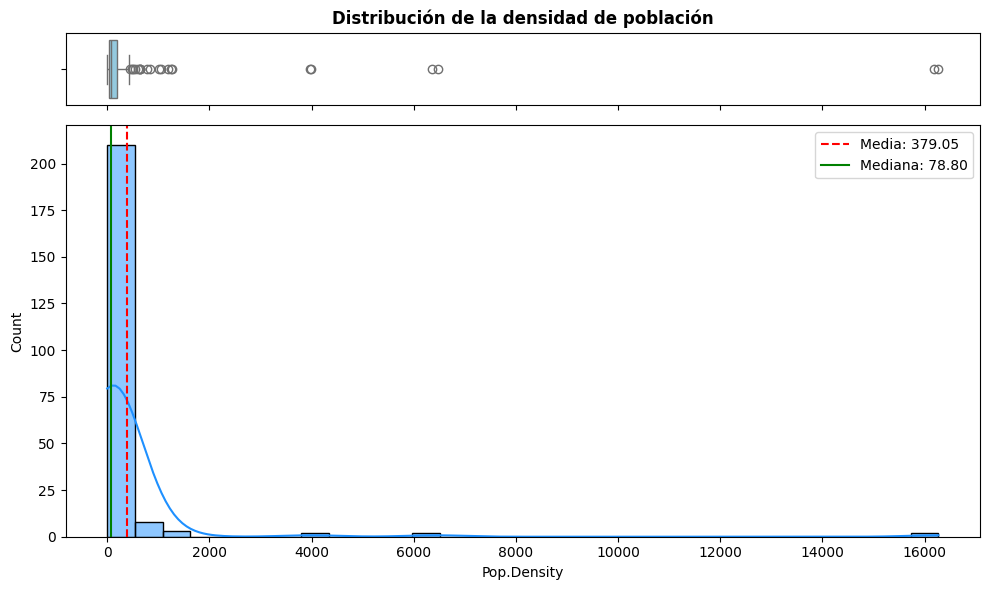

In [13]:
plot_distribucion_series(data_gdp["Pop.Density"],
    titulo="Distribución de la densidad de población",
    bins=30
)

In [14]:
data_gdp["Pop.Density"].describe()


count      227.000000
mean       379.047137
std       1660.185825
min          0.000000
25%         29.150000
50%         78.800000
75%        190.150000
max      16271.500000
Name: Pop.Density, dtype: float64

**Conclusiones (variable `Pop.Density`)**

Los gráficos y los estadísticos descriptivos muestran que la variable `Pop.Density` presenta una **distribución fuertemente asimétrica a la derecha**. El histograma evidencia que la gran mayoría de los países se concentra en valores bajos de densidad de población, mientras que existe una cola larga hacia valores muy elevados.

El boxplot aparece visualmente comprimido debido a que el **rango intercuartílico es reducido** en comparación con los valores extremos. En concreto, el 50 % central de los países presenta densidades comprendidas aproximadamente entre 29 y 190 habitantes por unidad de superficie, mientras que se observan algunos países con densidades muy superiores, alcanzando valores máximos superiores a 16 000.

Esta elevada dispersión queda reflejada también en la diferencia entre la media (≈ 379) y la mediana (≈ 79), lo que confirma la presencia de valores extremos que influyen significativamente en la media. Dada la marcada asimetría de la distribución, en etapas posteriores del análisis podría considerarse la aplicación de **transformaciones de la variable** (por ejemplo, una transformación logarítmica) con el objetivo de mejorar la interpretabilidad y el comportamiento del modelo de regresión.

---


##### A.2.2.3. Análisis univariante de la variable `Coastline`

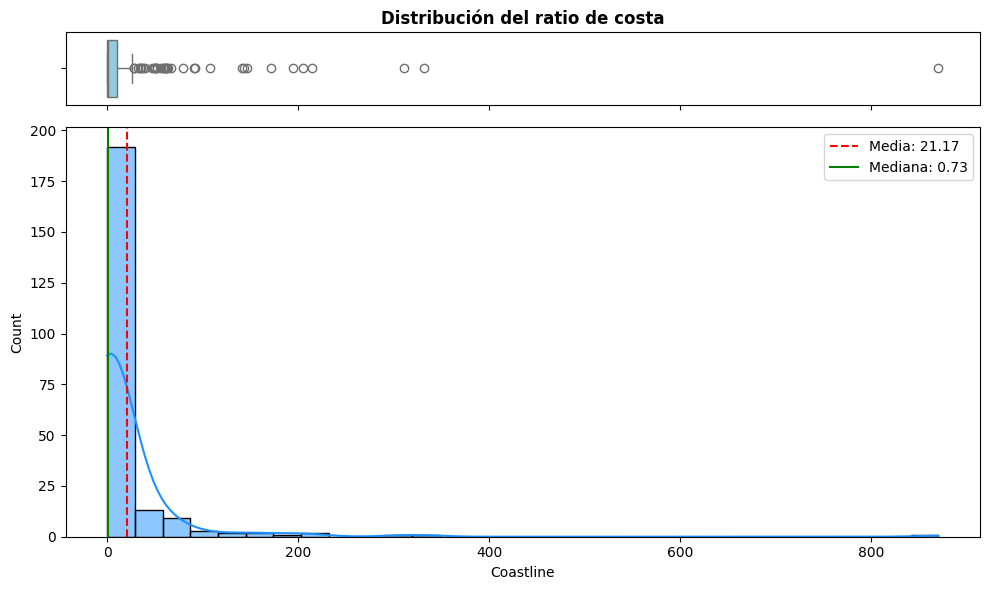

In [15]:
plot_distribucion_series(
    data_gdp["Coastline"],
    titulo="Distribución del ratio de costa",
    bins=30
)


In [16]:
data_gdp["Coastline"].describe()


count    227.000000
mean      21.165330
std       72.286863
min        0.000000
25%        0.100000
50%        0.730000
75%       10.345000
max      870.660000
Name: Coastline, dtype: float64

**Conclusiones (variable `Coastline`)**

La variable `Coastline` presenta una **distribución fuertemente asimétrica a la derecha**, tal y como se observa en el histograma, con una elevada concentración de países en valores cercanos a cero y una cola larga hacia valores altos. Esto indica que la mayoría de los países tienen un ratio de costa reducido, mientras que unos pocos presentan valores muy elevados, típicamente asociados a países insulares o con costas muy fragmentadas.

El boxplot confirma esta asimetría, mostrando un **rango intercuartílico muy reducido** en comparación con los valores extremos. En particular, la mediana se sitúa en torno a 0.73, y el tercer cuartil en aproximadamente 10.34, frente a un valor máximo que alcanza los 870.66. Esta diferencia explica la apariencia comprimida del boxplot y pone de manifiesto la presencia de **valores extremos elevados**.

La elevada diferencia entre la media (≈ 21.17) y la mediana refuerza la influencia de estos valores extremos sobre la distribución. Dada la marcada asimetría y la presencia de outliers, en etapas posteriores del análisis podría considerarse la aplicación de **transformaciones de la variable** (por ejemplo, una transformación logarítmica) con el fin de mejorar su comportamiento en el modelo de regresión.

---


##### A.2.2.4. Análisis univariante de la variable `Net.migration`

In [17]:
# Exclusión temporal de valores nulos únicamente para la visualización
net_migration_clean = data_gdp["Net.migration"].dropna()

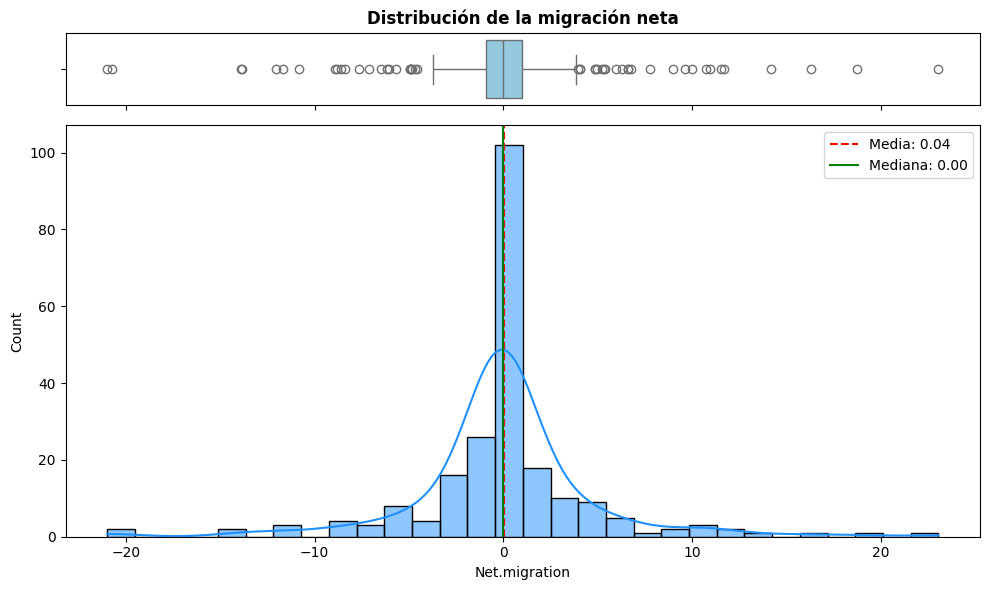

In [18]:
plot_distribucion_series(net_migration_clean,
    titulo="Distribución de la migración neta",
    bins=30
)

In [19]:
data_gdp["Net.migration"].describe()


count    224.000000
mean       0.038125
std        4.889269
min      -20.990000
25%       -0.927500
50%        0.000000
75%        0.997500
max       23.060000
Name: Net.migration, dtype: float64

**Conclusiones (variable `Net.migration`)**

La variable `Net.migration` presenta una distribución centrada en torno a cero, tal y como se observa tanto en el histograma como en los estadísticos descriptivos, lo que indica que, en promedio, los flujos migratorios netos tienden a equilibrarse entre países receptores y emisores.

El histograma muestra una distribución relativamente concentrada alrededor del valor central, aunque con **colas en ambos extremos**, reflejando la existencia de países con migración neta claramente negativa y otros con valores positivos elevados. El boxplot confirma la presencia de **valores extremos tanto positivos como negativos**, si bien el rango intercuartílico es relativamente reducido (aproximadamente entre −0.93 y 1.00).

La desviación estándar, notablemente superior al rango intercuartílico, pone de manifiesto la influencia de estos valores extremos sobre la dispersión global de la variable. En etapas posteriores del análisis podría evaluarse la conveniencia de aplicar **transformaciones** o tratamientos específicos para gestionar la presencia de outliers, especialmente si esta variable se incorpora al modelo de regresión.

---


##### A.2.2.4. Análisis univariante de la variable `Infant.mortality`

In [20]:
# Exclusión temporal de valores nulos únicamente para la visualización
infant_mortality_clean = data_gdp["Infant.mortality"].dropna()

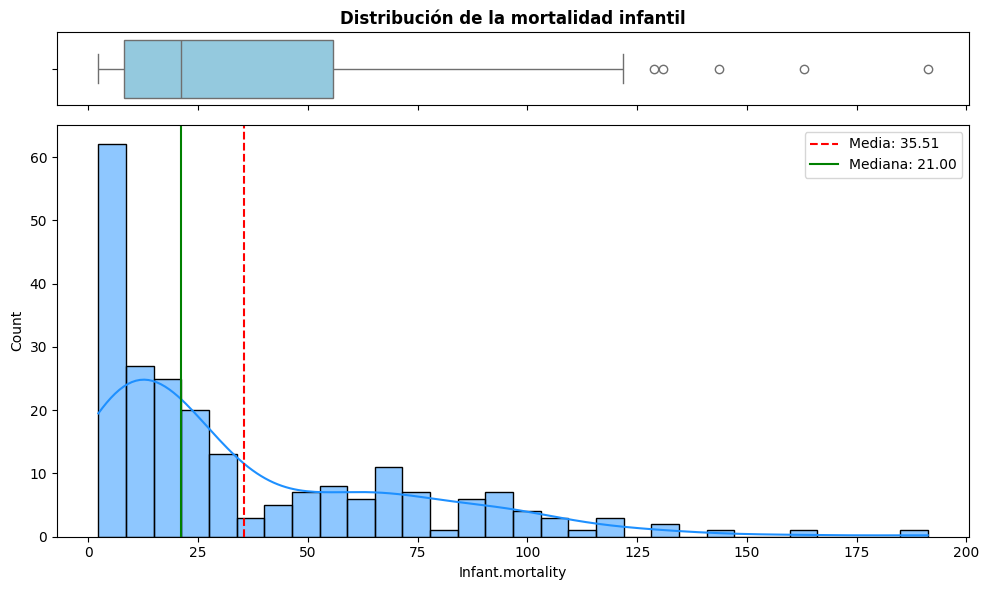

In [21]:
plot_distribucion_series(
    infant_mortality_clean,
    titulo="Distribución de la mortalidad infantil",
    bins=30
)

In [22]:
data_gdp["Infant.mortality"].describe()

count    224.000000
mean      35.506964
std       35.389899
min        2.290000
25%        8.150000
50%       21.000000
75%       55.705000
max      191.190000
Name: Infant.mortality, dtype: float64

La variable `Infant.mortality` presenta una **asimetría positiva marcada**, con una elevada concentración de países en valores bajos y una cola prolongada hacia valores altos, tal como se observa en el histograma.

El boxplot confirma la presencia de **valores extremos elevados**, con un rango intercuartílico aproximado entre 8.15 y 55.71 y un valor máximo cercano a 191. La mediana se sitúa alrededor de 21, lo que indica que la mayoría de los países presentan niveles relativamente bajos en comparación con los casos más extremos.

La diferencia entre la media (≈ 35.5) y la mediana pone de manifiesto la influencia de estos valores altos sobre la distribución. Dada esta asimetría y la presencia de outliers, resulta razonable considerar en etapas posteriores del análisis la aplicación de **transformaciones**, como la logarítmica, para mejorar el comportamiento de la variable en el modelo de regresión.

---

##### A.2.2.5. Análisis univariante de la variable `Literacy`

In [23]:
# Exclusión temporal de valores nulos únicamente para la visualización
literacy_clean = data_gdp["Literacy"].dropna()

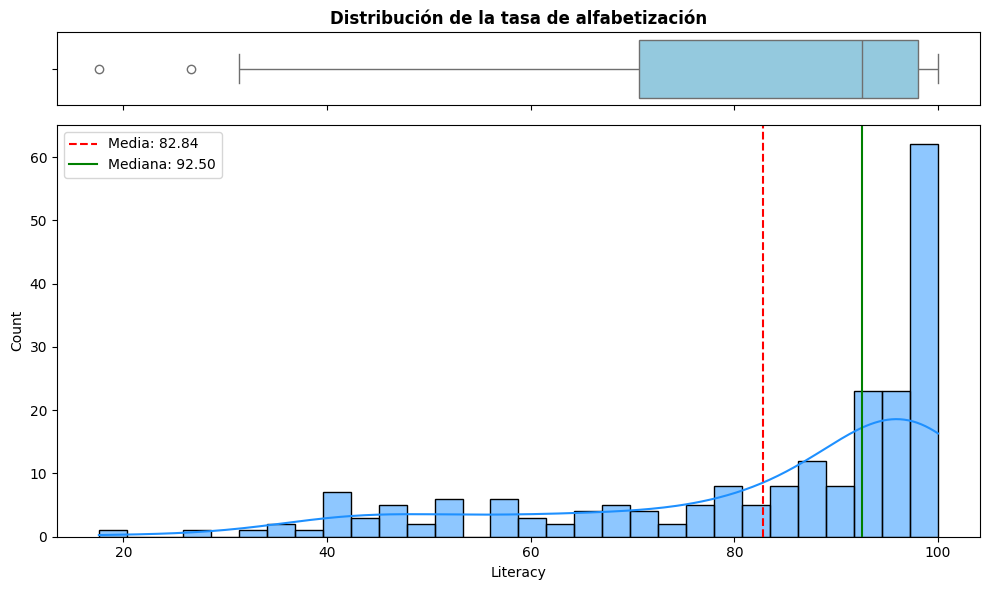

In [24]:
plot_distribucion_series(literacy_clean,
    titulo="Distribución de la tasa de alfabetización",
    bins=30
)

In [25]:
data_gdp["Literacy"].describe()

count    209.000000
mean      82.838278
std       19.722173
min       17.600000
25%       70.600000
50%       92.500000
75%       98.000000
max      100.000000
Name: Literacy, dtype: float64

**Conclusiones (variable Literacy)**

La variable `Literacy` presenta una distribución **asimétrica a la izquierda**, con una elevada concentración de países en valores altos de tasa de alfabetización. El histograma muestra que la mayoría de los países se sitúan por encima del 70 %, con un número considerable alcanzando valores cercanos al máximo del 100 %.

El boxplot confirma este comportamiento, situando la mediana en torno al 92.5 %, y mostrando un rango intercuartílico relativamente reducido (aproximadamente entre 70.6 % y 98.0 %). Se observan algunos valores bajos que actúan como **valores extremos**, correspondientes a países con tasas de alfabetización significativamente inferiores al resto.

La diferencia entre la media (≈ 82.8 %) y la mediana refuerza la asimetría negativa de la distribución. Dado que se trata de una variable acotada entre 0 y 100, en etapas posteriores del análisis podría valorarse la aplicación de **transformaciones específicas para variables proporcionales** o, alternativamente, su uso sin transformar si el comportamiento del modelo lo permite.

---

##### A.2.2.5. Análisis univariante de la variable `Phones`

In [26]:
# Exclusión temporal de valores nulos únicamente para la visualización
phones_clean = data_gdp["Phones"].dropna()

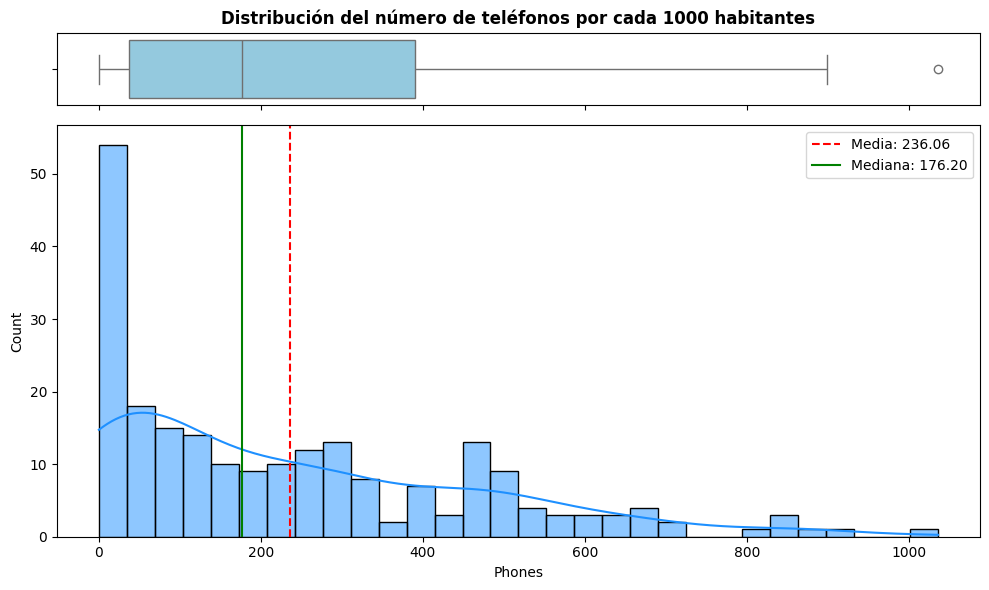

In [27]:
plot_distribucion_series(phones_clean,
    titulo="Distribución del número de teléfonos por cada 1000 habitantes",
    bins=30
)

In [28]:
data_gdp["Phones"].describe()

count     223.000000
mean      236.061435
std       227.991829
min         0.200000
25%        37.800000
50%       176.200000
75%       389.650000
max      1035.600000
Name: Phones, dtype: float64


La variable `Phones` presenta una **distribución claramente asimétrica a la derecha**, como se observa en el histograma, con una elevada concentración de países en valores bajos de número de teléfonos por cada 1000 habitantes y una cola larga hacia valores altos. Este patrón refleja las importantes diferencias en el grado de desarrollo de infraestructuras de telecomunicaciones entre países.

El boxplot confirma la presencia de **valores extremos elevados**, con un rango intercuartílico comprendido aproximadamente entre 37.8 y 389.65, mientras que el valor máximo alcanza 1 035.6. La mediana se sitúa en torno a 176.2, muy por debajo del valor máximo, lo que pone de manifiesto la elevada dispersión de la variable.

La diferencia entre la media (≈ 236.1) y la mediana refuerza la asimetría positiva de la distribución y la influencia de los valores extremos. Dada esta asimetría y la amplitud del rango de valores, en etapas posteriores del análisis podría considerarse la aplicación de **transformaciones de la variable** (por ejemplo, una transformación logarítmica) con el objetivo de mejorar su comportamiento en el modelo de regresión.

---


##### A.2.2.6. Análisis univariante de la variable `Birthrate`

In [29]:
# Exclusión temporal de valores nulos únicamente para la visualización
birthrate_clean = data_gdp["Birthrate"].dropna()

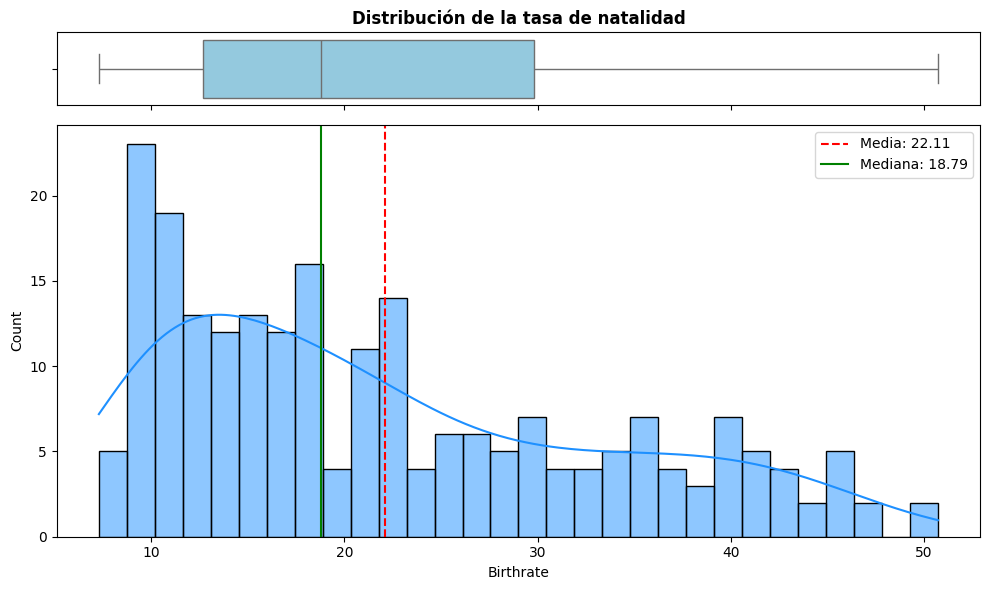

In [30]:
plot_distribucion_series(birthrate_clean,
    titulo="Distribución de la tasa de natalidad",
    bins=30
)

In [31]:
data_gdp["Birthrate"].describe()

count    224.000000
mean      22.114732
std       11.176716
min        7.290000
25%       12.672500
50%       18.790000
75%       29.820000
max       50.730000
Name: Birthrate, dtype: float64


La variable `Birthrate` presenta una **distribución asimétrica a la derecha**, tal y como se observa en el histograma, con una mayor concentración de países en valores bajos y medios de tasa de natalidad y una cola que se extiende hacia valores más elevados.

El boxplot muestra un rango intercuartílico comprendido aproximadamente entre 12.67 y 29.82, con una mediana situada en torno a 18.79. La presencia de valores elevados, cercanos al máximo observado (50.73), indica una dispersión considerable entre países, aunque sin una acumulación extrema de outliers claramente diferenciados.

La diferencia entre la media (≈ 22.11) y la mediana refuerza la asimetría positiva de la distribución. Dada esta asimetría y la amplitud del rango de valores, en etapas posteriores del análisis podría considerarse la aplicación de **transformaciones de la variable** con el objetivo de mejorar su comportamiento en el modelo de regresión, si así lo requieren los supuestos del modelo.

---


##### A.2.2.7. Análisis univariante de la variable `Deathrate`

In [32]:
# Exclusión temporal de valores nulos únicamente para la visualización
deathrate_clean = data_gdp["Deathrate"].dropna()

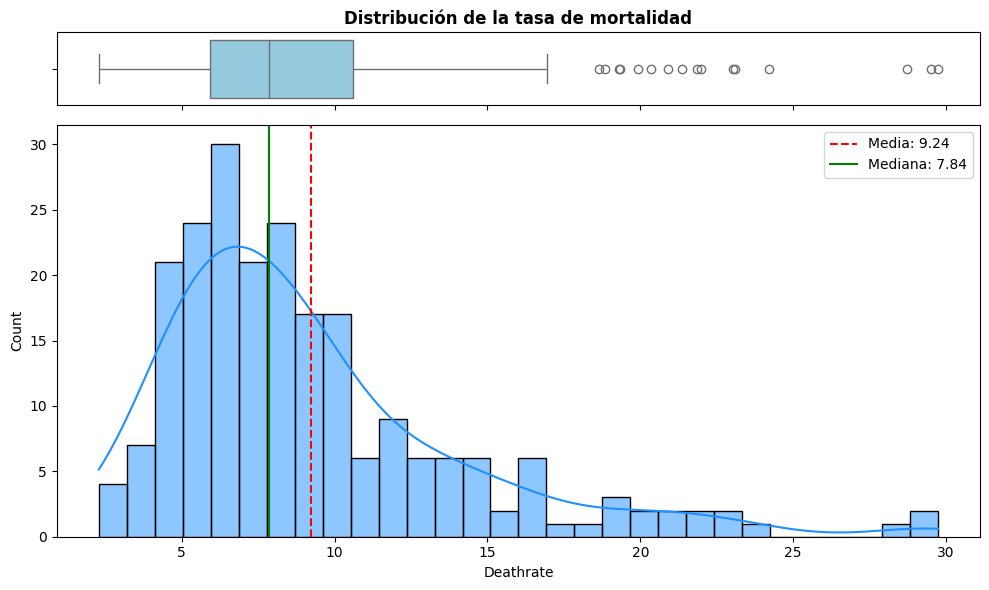

In [33]:
plot_distribucion_series(deathrate_clean,
    titulo="Distribución de la tasa de mortalidad",
    bins=30
)

In [34]:
data_gdp["Deathrate"].describe()

count    223.000000
mean       9.241345
std        4.990026
min        2.290000
25%        5.910000
50%        7.840000
75%       10.605000
max       29.740000
Name: Deathrate, dtype: float64


La variable `Deathrate` presenta una **distribución ligeramente asimétrica a la derecha**, como se observa en el histograma, con una mayor concentración de países en valores bajos y medios de la tasa de mortalidad y una cola que se extiende hacia valores más elevados.

El boxplot muestra un rango intercuartílico relativamente moderado, comprendido aproximadamente entre 5.91 y 10.61, con una mediana situada en torno a 7.84. Se observan **valores extremos elevados**, con tasas de mortalidad cercanas al máximo observado (29.74), que explican la asimetría positiva de la distribución.

La diferencia entre la media (≈ 9.24) y la mediana confirma la influencia de estos valores elevados sobre la distribución. Aunque la asimetría es menos pronunciada que en otras variables analizadas, en etapas posteriores del análisis podría valorarse la aplicación de **transformaciones de la variable** o tratamientos específicos de outliers si fuera necesario para mejorar el ajuste del modelo de regresión.

---


##### A.2.2.8. Análisis univariante de la variable `Agriculture`

In [35]:
# Exclusión temporal de valores nulos únicamente para la visualización
agriculture_clean = data_gdp["Agriculture"].dropna()

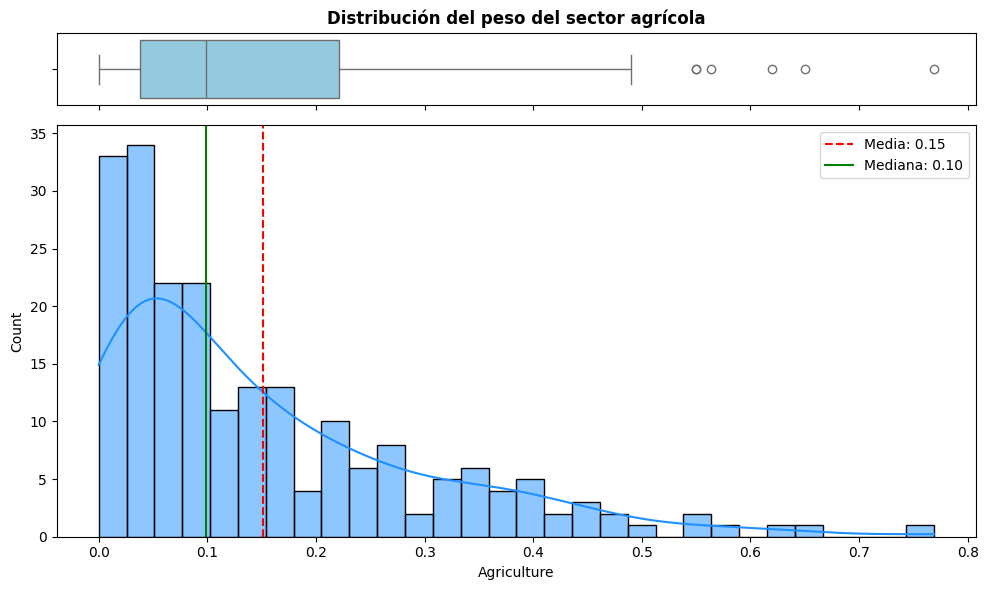

In [36]:
plot_distribucion_series(agriculture_clean,
    titulo="Distribución del peso del sector agrícola",
    bins=30
)

In [37]:
data_gdp["Agriculture"].describe()

count    212.000000
mean       0.150844
std        0.146798
min        0.000000
25%        0.037750
50%        0.099000
75%        0.221000
max        0.769000
Name: Agriculture, dtype: float64


La variable `Agriculture` presenta una **distribución claramente asimétrica a la derecha**, como se observa en el histograma, con una alta concentración de países en valores bajos del peso del sector agrícola sobre el PIB y una cola larga hacia valores más elevados.

El boxplot confirma la presencia de **valores extremos elevados**, con un rango intercuartílico comprendido aproximadamente entre 0.038 y 0.221, y una mediana situada en torno a 0.099. El valor máximo alcanza aproximadamente 0.769, lo que indica que en algunos países el sector agrícola representa una proporción muy elevada de la actividad económica.

La diferencia entre la media (≈ 0.151) y la mediana refuerza la asimetría positiva de la distribución y la influencia de los valores extremos. Dado que se trata de una variable proporcional y que su relación con la variable objetivo es monótona y estable, no se considera necesaria la aplicación de transformaciones adicionales en esta etapa del análisis.

---


##### A.2.2.9. Análisis univariante de la variable `Industry`

In [38]:
# Exclusión temporal de valores nulos únicamente para la visualización
industry_clean = data_gdp["Industry"].dropna()

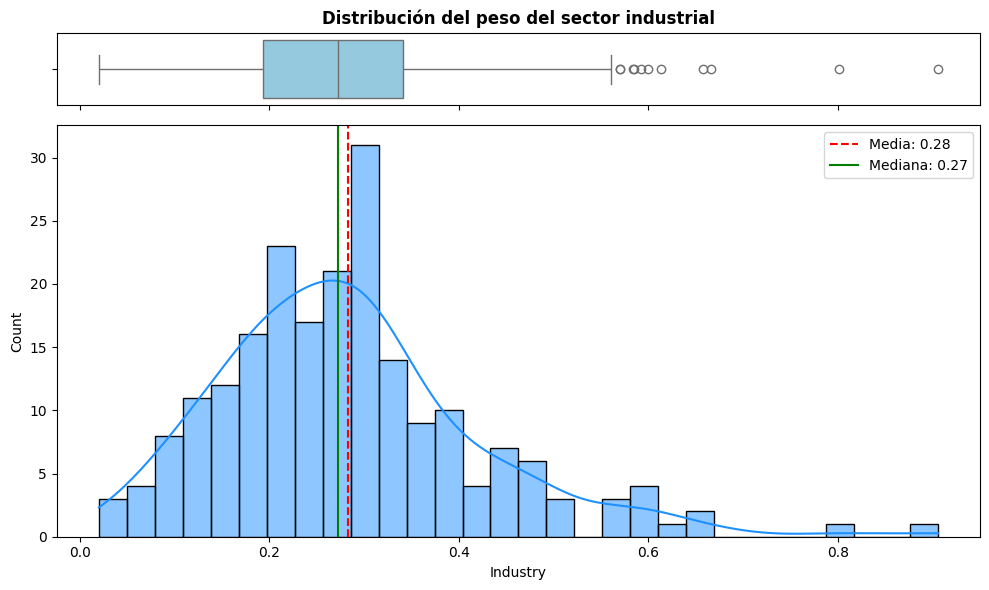

In [39]:
plot_distribucion_series(industry_clean,
    titulo="Distribución del peso del sector industrial",
    bins=30
)

In [40]:
data_gdp["Industry"].describe()

count    211.000000
mean       0.282711
std        0.138272
min        0.020000
25%        0.193000
50%        0.272000
75%        0.341000
max        0.906000
Name: Industry, dtype: float64


La variable `Industry` presenta una distribución relativamente concentrada en valores intermedios, con una **ligera asimetría a la derecha**, tal y como se observa en el histograma. La mayoría de los países muestran un peso del sector industrial comprendido aproximadamente entre 0.2 y 0.4 del PIB.

El boxplot muestra un rango intercuartílico acotado, entre aproximadamente 0.193 y 0.341, con una mediana situada en torno a 0.272. Se observan **valores extremos elevados**, con algunos países alcanzando valores cercanos al máximo observado (0.906), lo que indica una especialización industrial muy marcada en casos concretos.

La diferencia moderada entre la media (≈ 0.283) y la mediana sugiere que la influencia de los valores extremos es menos acusada que en otras variables de composición sectorial, aunque sigue siendo relevante. Dado que se trata de una variable proporcional y que su relación con la variable objetivo es monótona y estable, no se considera necesaria la aplicación de transformaciones adicionales en esta etapa del análisis.

---


##### A.2.2.10. Análisis univariante de la variable `Service`

In [41]:
# Exclusión temporal de valores nulos únicamente para la visualización
service_clean = data_gdp["Service"].dropna()

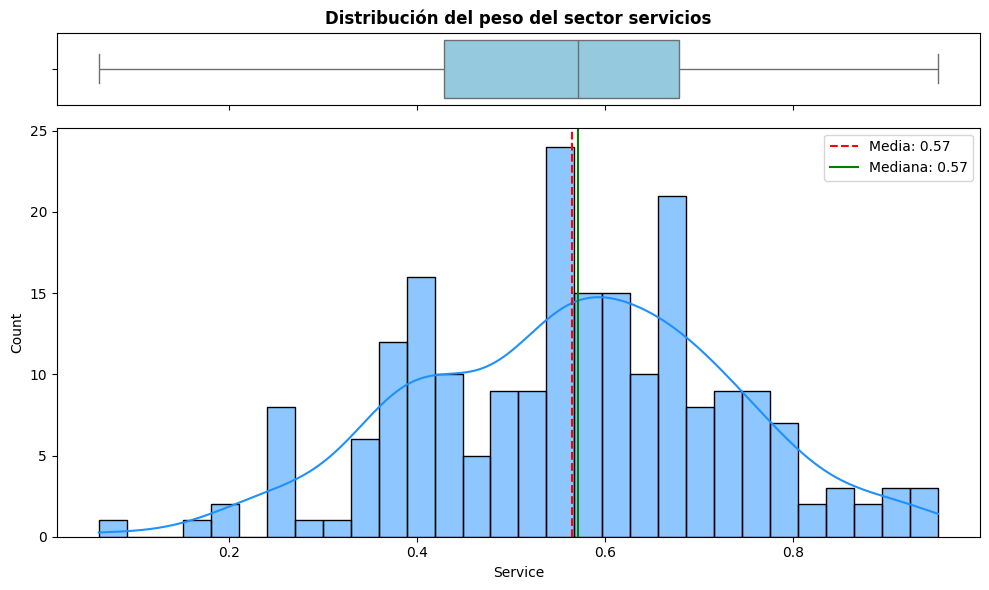

In [42]:
plot_distribucion_series(service_clean,
    titulo="Distribución del peso del sector servicios",
    bins=30
)

In [43]:
data_gdp["Service"].describe()

count    212.000000
mean       0.565283
std        0.165841
min        0.062000
25%        0.429250
50%        0.571000
75%        0.678500
max        0.954000
Name: Service, dtype: float64


La variable `Service` presenta una distribución relativamente concentrada en valores altos del peso del sector servicios sobre el PIB, tal y como se observa en el histograma. La mayoría de los países se sitúan en torno a valores comprendidos entre 0.4 y 0.7, lo que refleja la importancia del sector servicios en la estructura económica de la mayoría de las economías.

El boxplot muestra un rango intercuartílico comprendido aproximadamente entre 0.429 y 0.679, con una mediana situada en torno a 0.571. A diferencia de otras variables de composición sectorial, no se observan valores extremos especialmente pronunciados, lo que indica una **dispersión moderada y una distribución relativamente equilibrada**.

La cercanía entre la media (≈ 0.565) y la mediana refuerza la idea de una distribución relativamente simétrica. Dado que se trata de una variable proporcional y que su relación con la variable objetivo es monótona y estable, no se considera necesaria la aplicación de transformaciones adicionales en esta etapa del análisis.

---


##### A.2.2.11. Análisis univariante de la variable `Arable`

In [44]:
# Exclusión temporal de valores nulos únicamente para la visualización
arable_clean = data_gdp["Arable"].dropna()

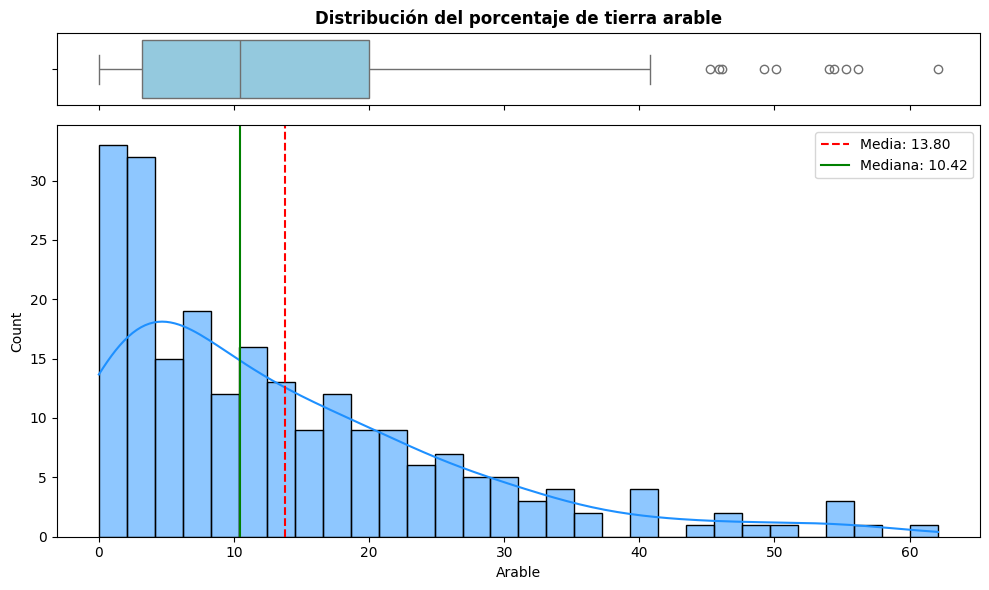

In [45]:
plot_distribucion_series(arable_clean,
    titulo="Distribución del porcentaje de tierra arable",
    bins=30
)

In [46]:
data_gdp["Arable"].describe()

count    225.000000
mean      13.797111
std       13.040402
min        0.000000
25%        3.220000
50%       10.420000
75%       20.000000
max       62.110000
Name: Arable, dtype: float64


La variable `Arable` presenta una **distribución claramente asimétrica a la derecha**, como se observa en el histograma, con una alta concentración de países en valores bajos del porcentaje de tierra arable y una cola larga hacia valores más elevados.

El boxplot muestra un rango intercuartílico comprendido aproximadamente entre 3.22 y 20.0, con una mediana situada en torno a 10.42. Se observan **valores extremos elevados**, con porcentajes de tierra arable que superan el 50 % en algunos países, lo que explica la elevada dispersión de la variable.

La diferencia entre la media (≈ 13.8) y la mediana refuerza la asimetría positiva de la distribución. Dada la marcada asimetría y la amplitud del rango de valores, en etapas posteriores del análisis podría considerarse la aplicación de **transformaciones de la variable** (por ejemplo, transformaciones logarítmicas o específicas para proporciones) con el fin de mejorar su comportamiento en el modelo de regresión.

---


##### A.2.2.12. Análisis univariante de la variable `Crops`

In [47]:
# Exclusión temporal de valores nulos únicamente para la visualización
crops_clean = data_gdp["Crops"].dropna()

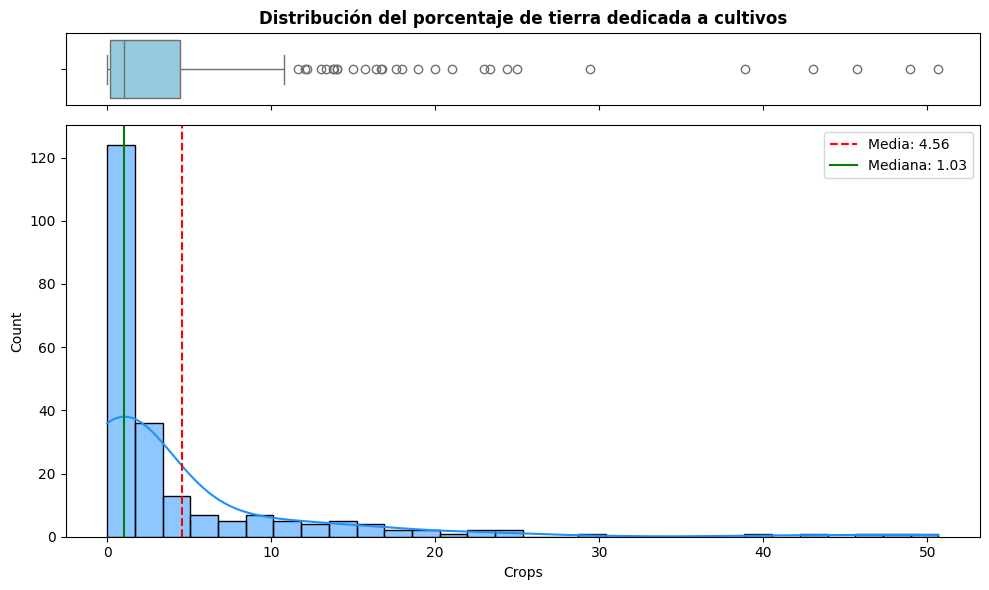

In [48]:
plot_distribucion_series(crops_clean,
    titulo="Distribución del porcentaje de tierra dedicada a cultivos",
    bins=30
)

In [49]:
data_gdp["Crops"].describe()

count    225.000000
mean       4.564222
std        8.361470
min        0.000000
25%        0.190000
50%        1.030000
75%        4.440000
max       50.680000
Name: Crops, dtype: float64


La variable `Crops` presenta una **distribución fuertemente asimétrica a la derecha**, como se observa en el histograma, con una elevada concentración de países en valores muy bajos del porcentaje de tierra dedicada a cultivos y una cola larga hacia valores más elevados.

El boxplot muestra un rango intercuartílico muy reducido, con la mediana situada en torno a 1.03 y el tercer cuartil en aproximadamente 4.44. Sin embargo, se observan **numerosos valores extremos elevados**, con porcentajes de tierra dedicada a cultivos que superan ampliamente el 20 % y alcanzan valores máximos superiores al 50 %.

La diferencia entre la media (≈ 4.56) y la mediana confirma la fuerte asimetría positiva de la distribución y la influencia de los valores extremos sobre la dispersión global. Dada esta marcada asimetría y la presencia de outliers, en etapas posteriores del análisis podría considerarse la aplicación de **transformaciones de la variable** (por ejemplo, transformaciones logarítmicas o específicas para proporciones) con el fin de mejorar su comportamiento en el modelo de regresión.

---


##### A.2.2.13. Análisis univariante de la variable `Other`

In [50]:
# Exclusión temporal de valores nulos únicamente para la visualización
other_clean = data_gdp["Other"].dropna()

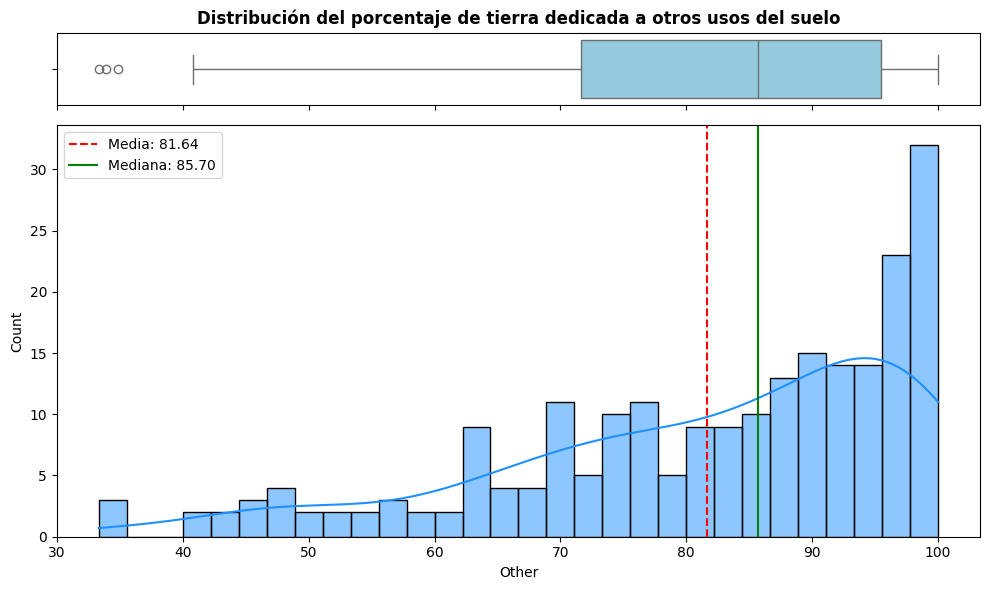

In [51]:
plot_distribucion_series(other_clean,
    titulo="Distribución del porcentaje de tierra dedicada a otros usos del suelo",
    bins=30
)

In [52]:
data_gdp["Other"].describe()

count    225.000000
mean      81.638311
std       16.140835
min       33.330000
25%       71.650000
50%       85.700000
75%       95.440000
max      100.000000
Name: Other, dtype: float64


La variable `Other` presenta una **distribución asimétrica a la izquierda**, como se observa en el histograma, con una elevada concentración de países en valores altos del porcentaje de otros usos del suelo y una cola que se extiende hacia valores más bajos.

El boxplot muestra un rango intercuartílico relativamente amplio, comprendido aproximadamente entre 71.65 y 95.44, con una mediana situada en torno a 85.7. Se observan algunos valores bajos que actúan como **valores extremos**, correspondientes a países en los que la proporción de suelo dedicado a otros usos es sensiblemente menor.

La diferencia entre la media (≈ 81.6) y la mediana refuerza la asimetría negativa de la distribución. Dado que `Other` forma parte, junto con `Arable` y `Crops`, de una descomposición del uso del suelo y se trata de una variable acotada entre 0 y 100, en etapas posteriores del análisis podría considerarse la aplicación de **transformaciones específicas para variables proporcionales**, aunque su comportamiento actual sugiere que puede incorporarse al modelo sin transformaciones adicionales.

---


#### A.2.3. Análisis gráfico de las variables discretas

In [53]:
(data_gdp["Population"] % 1 == 0).all()

np.True_

Todos los valores de `Population` son enteros, por lo que se corresponde a un conteo

In [54]:
(data_gdp["Area"] % 1 == 0).all()

np.True_

Todos los valores de `Area` son enteros, por lo que se corresponde a un conteo

Dada la escala extremadamente amplia de las variables `Population` y `Area`, su distribución en niveles no resulta informativa. Por este motivo, con **fines exclusivamente descriptivos**, se representa adicionalmente en escala logarítmica para facilitar la visualización de su estructura

---

##### A.2.3.1. Análisis univariante de `Population`

In [55]:
# plot_distribucion_series(
#     data_gdp["Population"],
#     titulo="Distribución de la población"
# )

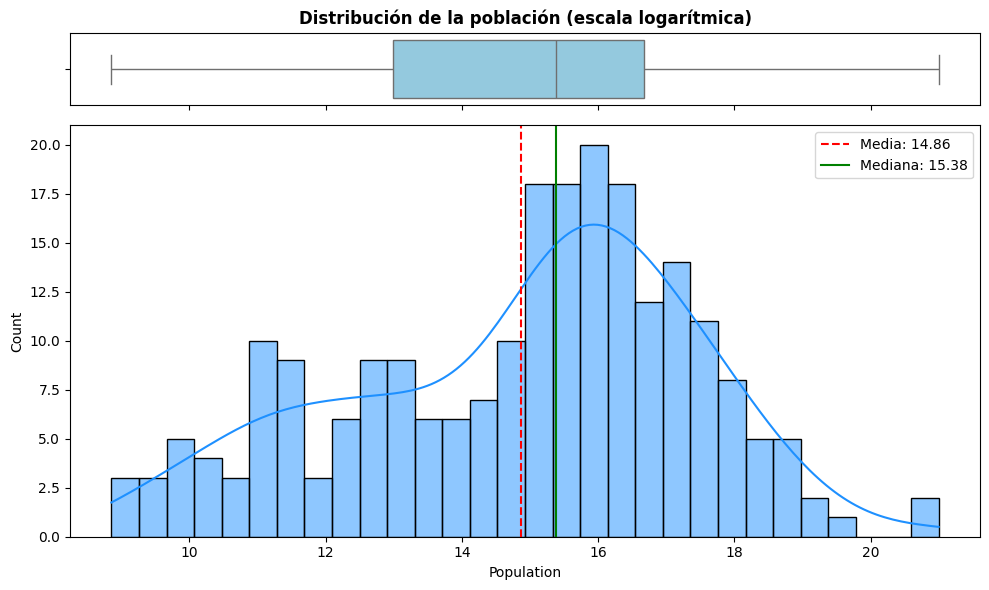

In [56]:
population_log = np.log(data_gdp["Population"].dropna()) # Exclusión temporal de valores nulos únicamente para la visualización y transformación logarítmica

plot_distribucion_series(
    population_log,
    titulo="Distribución de la población (escala logarítmica)"
)

In [57]:
population_log.describe()

count    227.000000
mean      14.863932
std        2.543368
min        8.857373
25%       12.989110
50%       15.381413
75%       16.677544
max       20.996322
Name: Population, dtype: float64

La variable `Population`, analizada en **escala logarítmica**, presenta una distribución relativamente equilibrada, aunque con una **ligera asimetría negativa**, como se observa en el histograma. La mayor concentración de países se sitúa en valores medios-altos de `log(Population)`, mientras que la cola de la distribución se extiende hacia valores más bajos, correspondientes a países con poblaciones reducidas.

El boxplot muestra un rango intercuartílico moderado, aproximadamente comprendido entre 12.99 y 16.68, con una mediana situada en torno a 15.38. Se observan algunos valores extremos en ambos extremos de la distribución, especialmente en la parte inferior, asociados a países con poblaciones muy pequeñas incluso tras la transformación logarítmica.

La diferencia entre la media (≈ 14.86) y la mediana refuerza la presencia de una ligera asimetría negativa. La transformación logarítmica aplicada resulta adecuada, ya que reduce la elevada asimetría presente en la escala original y permite una representación más informativa de la distribución. En este contexto, el comportamiento de `log(Population)` sugiere que la variable puede incorporarse de forma razonable en el análisis posterior, evitando los problemas derivados de la gran dispersión y de los valores extremos observados en niveles.

##### A.2.3.2. Análisis univariante de `Area`

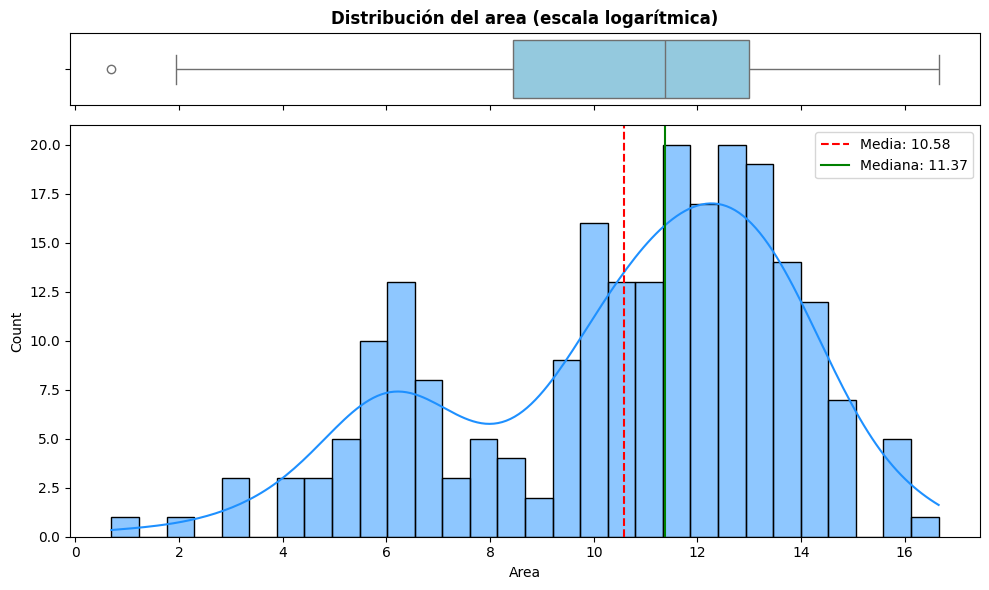

In [58]:
area_log = np.log(data_gdp["Area"].dropna()) # Exclusión temporal de valores nulos únicamente para la visualización y transformación logarítmica

plot_distribucion_series(
    area_log,
    titulo="Distribución del area (escala logarítmica)"
)

In [59]:
area_log.describe()

count    227.000000
mean      10.579202
std        3.192399
min        0.693147
25%        8.438711
50%       11.369055
75%       12.998580
max       16.653138
Name: Area, dtype: float64

La variable `Area`, analizada en **escala logarítmica con fines descriptivos**, presenta una distribución relativamente dispersa, reflejo de la gran heterogeneidad existente en la superficie de los países. El histograma muestra una concentración principal de observaciones en valores intermedios, junto con una cola que se extiende hacia valores más bajos, correspondientes a países de muy reducida extensión territorial.

El boxplot evidencia un rango intercuartílico comprendido aproximadamente entre 8.44 y 13.00, con una mediana situada en torno a 11.37. Se identifican algunos valores extremos en la parte inferior de la distribución, asociados a países o territorios de tamaño excepcionalmente pequeño, que persisten incluso tras la transformación logarítmica.

La diferencia entre la media (≈ 10.58) y la mediana confirma una **ligera asimetría negativa** en la distribución. La utilización de la escala logarítmica permite una representación más informativa de la variable, evitando que los países de gran superficie dominen la visualización y facilitando una descripción más equilibrada de la distribución del área geográfica en el conjunto de datos.

#### A.2.4. Análisis gráfico de las variables categóricas

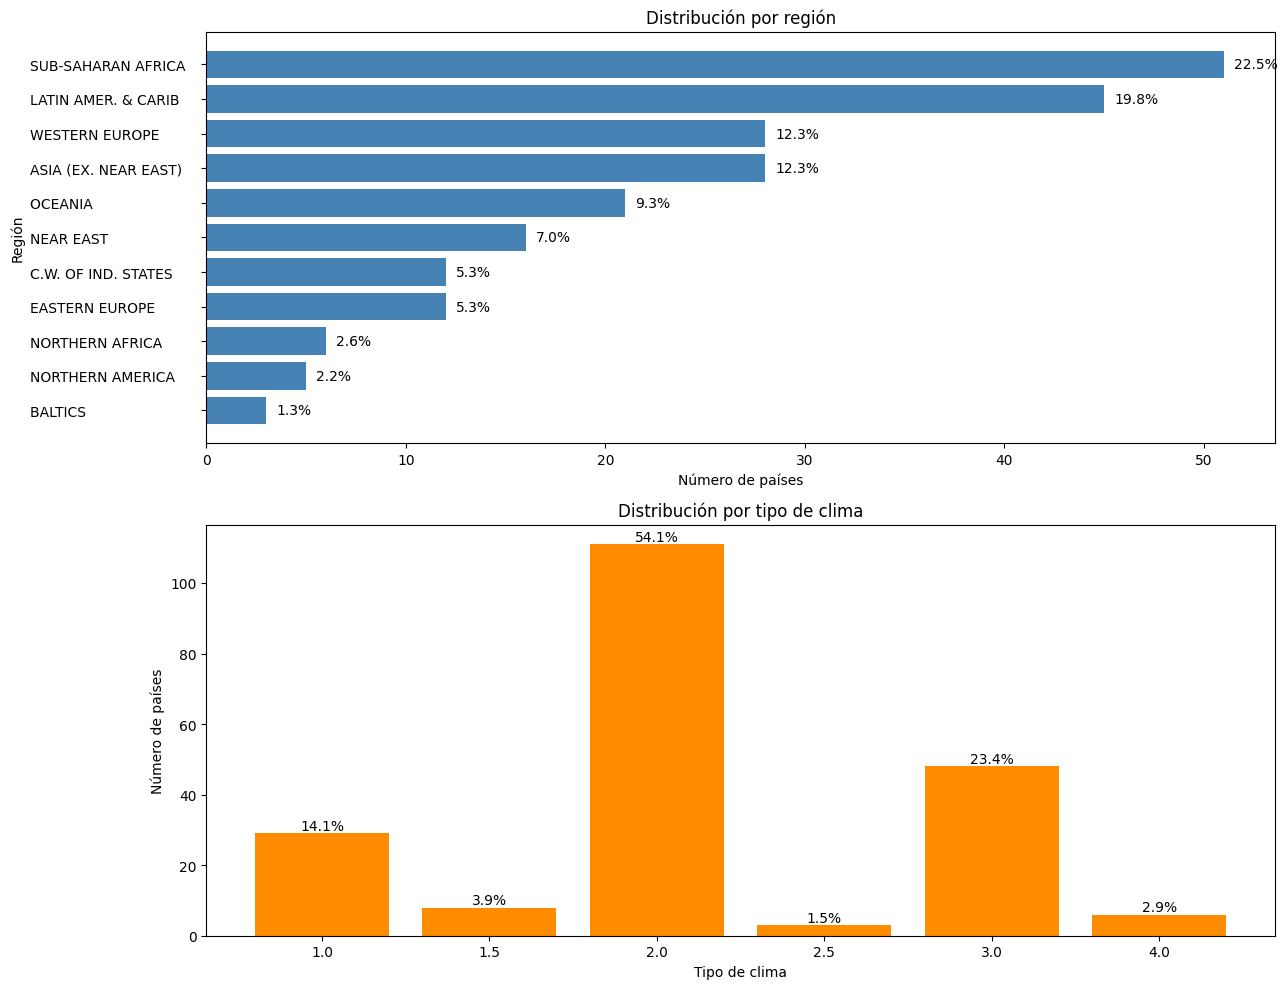

In [60]:
import matplotlib.transforms as mtransforms

fig, axes = plt.subplots(2, 1, figsize=(13, 10)) 
# ===================== REGION =====================
region_counts = data_gdp["Region"].value_counts().sort_values()
total_countries = region_counts.sum()

y = np.arange(len(region_counts))
axes[0].barh(y, region_counts.values, color="steelblue")
axes[0].set_title("Distribución por región")
axes[0].set_xlabel("Número de países")
axes[0].set_ylabel("Región")
axes[0].set_yticks(y)
axes[0].set_yticklabels(region_counts.index)

# Alineación izquierda de etiquetas del eje Y
axes[0].yaxis.set_ticks_position('left')

dx = -120
offset = mtransforms.ScaledTranslation(dx/72, 0, fig.dpi_scale_trans)
for label in axes[0].get_yticklabels():
    label.set_horizontalalignment('left')
    label.set_transform(label.get_transform() + offset)

# Porcentajes sobre las barras (REGIÓN)
for i, value in enumerate(region_counts.values):
    pct = value / total_countries * 100
    axes[0].text(
        value + 0.5,
        i,
        f"{pct:.1f}%",
        va="center"
    )

# ===================== CLIMATE =====================
climate_counts = data_gdp["Climate"].value_counts().sort_index()
total_countries_climate = climate_counts.sum()

axes[1].bar(climate_counts.index.astype(str),
            climate_counts.values,
            color="darkorange")

axes[1].set_title("Distribución por tipo de clima")
axes[1].set_xlabel("Tipo de clima")
axes[1].set_ylabel("Número de países")

# Porcentajes sobre las barras (CLIMA)
for i, value in enumerate(climate_counts.values):
    pct = value / total_countries_climate * 100
    axes[1].text(
        i,
        value + 1,
        f"{pct:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()





### A.3 Análisis bivariante y multivariante exploratorio

#### A.3.1. Análisis bivariante y multivariante exploratorio de variables explicativas continuas

##### Objetivo del apartado

El objetivo de este apartado es analizar las **relaciones bivariantes y multivariantes entre las variables numéricas** del conjunto de datos, con especial atención a la relación entre la variable objetivo `GDP` y las variables explicativas continuas. Este análisis se utiliza para identificar asociaciones lineales o no lineales relevantes, evaluar la intensidad de dichas relaciones y detectar posibles problemas de colinealidad entre variables explicativas.

Asimismo, este apartado tiene como finalidad **seleccionar de forma razonada** un subconjunto de variables para su análisis multivariante detallado, apoyándose en el estudio previo de correlaciones. De este modo, el análisis bivariante y multivariante sirve como base para orientar decisiones posteriores relativas a la transformación de variables, la selección de características y la especificación del modelo de regresión.

Las variables categóricas puras, como `Climate`, no se incluyen en el análisis de correlación ni en el diagrama de dispersión por pares, dado que su codificación numérica no representa una escala continua y no resulta adecuada para este tipo de análisis.

---

##### Metodología

Para llevar a cabo este análisis se emplea un enfoque exploratorio en dos etapas:

- En primer lugar, se analiza la **matriz de correlaciones entre las variables numéricas continuas**, representada mediante un mapa de calor (*heatmap*). Este análisis permite identificar las variables con mayor asociación con la variable objetivo `GDP`, así como detectar posibles relaciones de colinealidad entre variables explicativas.

- A partir de los resultados del análisis de correlación, se selecciona un **subconjunto reducido de variables continuas relevantes**, atendiendo a criterios de interpretabilidad, relevancia económica y ausencia de redundancia. Sobre este subconjunto se representa un **diagrama de dispersión por pares (*pairplot*)**, con el objetivo de explorar de forma conjunta las relaciones entre las variables seleccionadas y confirmar visualmente los patrones detectados en la matriz de correlaciones.

Este enfoque permite evitar la repetición de gráficos individuales, proporciona una visión global de las relaciones relevantes y facilita la interpretación de los datos en el contexto del posterior ajuste del modelo de regresión.

---

##### A.3.1.1. Matriz de correlaciones entre variables numéricas

Para mejorar la legibilidad de la matriz de correlaciones y evitar información redundante, se representa únicamente el triángulo inferior de la matriz, manteniendo los valores numéricos de correlación.

In [61]:
# Selección de variables numéricas
numeric_vars = data_gdp.select_dtypes(include=["float64", "int64"]).copy()

# Excluir variables categóricas codificadas o no adecuadas para correlación
numeric_vars = numeric_vars.drop(columns=["Climate"], errors="ignore")

numeric_vars.head()


,Population,Area,Pop.Density,Coastline,Net.migration,Infant.mortality,GDP,Literacy,Phones,Arable,Crops,Other,Birthrate,Deathrate,Agriculture,Industry,Service
0,31056997,647500,48.0,0.00,23.06,163.07,700.0,36.0,3.2,12.13,0.22,87.65,46.60,20.34,0.380,0.240,0.380
1,3581655,28748,124.6,1.26,-4.93,21.52,4500.0,86.5,71.2,21.09,4.42,74.49,15.11,5.22,0.232,0.188,0.579
2,32930091,2381740,13.8,0.04,-0.39,31.00,6000.0,70.0,78.1,3.22,0.25,96.53,17.14,4.61,0.101,0.600,0.298
3,57794,199,290.4,58.29,-20.71,9.27,8000.0,97.0,259.5,10.00,15.00,75.00,22.46,3.27,NaN,NaN,NaN
4,71201,468,152.1,0.00,6.60,4.05,19000.0,100.0,497.2,2.22,0.00,97.78,8.71,6.25,NaN,NaN,NaN


In [62]:
corr_matrix = numeric_vars.corr()
corr_matrix


,Population,Area,Pop.Density,Coastline,Net.migration,Infant.mortality,GDP,Literacy,Phones,Arable,Crops,Other,Birthrate,Deathrate,Agriculture,Industry,Service
Population,1.000000,0.469985,-0.028190,-0.068199,0.000011,0.023003,-0.039324,-0.043481,-0.030819,0.188251,-0.060757,-0.120606,-0.045090,-0.028367,0.000376,0.099333,-0.080852
Area,0.469985,1.000000,-0.066917,-0.095627,0.047470,-0.007163,0.072185,0.035994,0.053403,-0.079714,-0.143916,0.138974,-0.066423,0.040079,-0.050640,0.121565,-0.054369
Pop.Density,-0.028190,-0.066917,1.000000,0.241690,0.178038,-0.144238,0.195773,0.097230,0.280172,-0.081015,-0.031661,0.081859,-0.159192,-0.070045,-0.107142,-0.139803,0.248774
Coastline,-0.068199,-0.095627,0.241690,1.000000,-0.134145,-0.136577,0.049118,0.117095,0.152129,-0.120772,0.341820,-0.079494,-0.075765,-0.161866,-0.030250,-0.199995,0.196528
Net.migration,0.000011,0.047470,0.178038,-0.134145,1.000000,-0.025015,0.382461,-0.008761,0.239601,-0.058170,-0.347968,0.225299,-0.066537,0.033611,-0.116719,-0.026324,0.127134
Infant.mortality,0.023003,-0.007163,-0.144238,-0.136577,-0.025015,1.000000,-0.600774,-0.765536,-0.672312,-0.113859,-0.062366,0.124100,0.845764,0.656338,0.709475,0.003322,-0.633982
GDP,-0.039324,0.072185,0.195773,0.049118,0.382461,-0.600774,1.000000,0.513144,0.834499,0.019768,-0.219229,0.097828,-0.650137,-0.201661,-0.586769,-0.028926,0.550216
Literacy,-0.043481,0.035994,0.097230,0.117095,-0.008761,-0.765536,0.513144,1.000000,0.601935,0.105021,0.042825,-0.107563,-0.790846,-0.393946,-0.609638,0.064733,0.494607
Phones,-0.030819,0.053403,0.280172,0.152129,0.239601,-0.672312,0.834499,0.601935,1.000000,0.061022,-0.152420,0.029900,-0.724614,-0.260309,-0.601739,-0.152452,0.683934
Arable,0.188251,-0.079714,-0.081015,-0.120772,-0.058170,-0.113859,0.019768,0.105021,0.061022,1.000000,0.094361,-0.856763,-0.186823,0.053472,-0.034822,-0.063618,0.091126


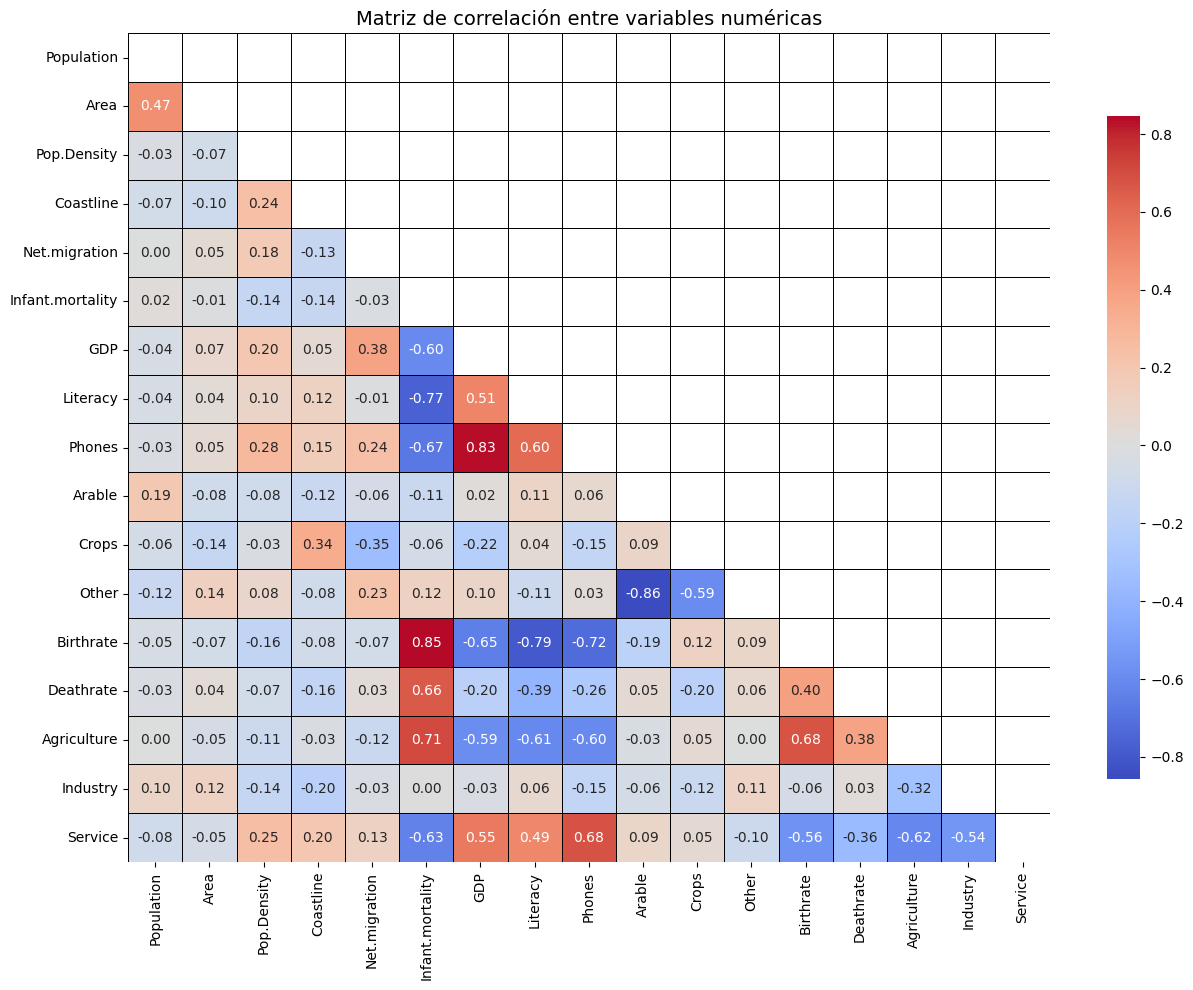

In [63]:
# Máscara para mostrar solo el triángulo inferior
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor="black",
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de correlación entre variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()




##### A.3.1.2. Interpretación de la matriz de correlaciones


El análisis de la matriz de correlaciones permite identificar patrones relevantes en las relaciones entre las variables numéricas, así como orientar la selección de variables para el análisis multivariante posterior.

##### Relación de las variables con la variable objetivo (GDP)

Se observan **correlaciones moderadas a fuertes** entre `GDP` y varias variables asociadas al nivel de desarrollo:

- `Phones` presenta una **correlación positiva elevada** con `GDP` (ρ ≈ 0.83), lo que sugiere una fuerte asociación entre el nivel de renta y el grado de desarrollo de infraestructuras de telecomunicaciones.
- `Literacy` muestra también una **correlación positiva moderada** (ρ ≈ 0.51), indicando que mayores niveles de alfabetización suelen asociarse a mayores niveles de PIB per cápita.
- `Service` presenta una **correlación positiva moderada** con `GDP` (ρ ≈ 0.55), coherente con economías más orientadas al sector servicios en países con mayor renta.
- `Infant.mortality` muestra una **correlación negativa significativa** con `GDP` (ρ ≈ −0.60), reflejando que mayores niveles de renta se asocian a menores tasas de mortalidad infantil.
- `Birthrate` y `Agriculture` presentan **correlaciones negativas moderadas** con `GDP` (ρ ≈ −0.65 y ρ ≈ −0.59, respectivamente), coherentes con patrones de transición demográfica y estructural.

En cambio, variables como `Population`, `Area`, `Coastline` o `Arable` muestran correlaciones muy reducidas con `GDP`, lo que sugiere una menor capacidad explicativa directa en niveles.

---

##### Detección de colinealidad entre variables explicativas

La matriz de correlaciones pone de manifiesto la existencia de **bloques de alta correlación entre variables explicativas**, lo que indica posibles problemas de colinealidad:

- `Infant.mortality`, `Birthrate` y `Agriculture` presentan **correlaciones positivas elevadas entre sí**, y correlaciones negativas fuertes con `Literacy`, `Phones` y `Service`. Esto sugiere que estas variables capturan dimensiones similares relacionadas con el nivel de desarrollo.
- `Literacy` y `Phones` están **fuertemente correlacionadas entre sí** (ρ ≈ 0.60), lo que aconseja no incluir ambas simultáneamente en un mismo modelo sin un análisis posterior de colinealidad.
- Las variables `Agriculture`, `Industry` y `Service` muestran relaciones negativas entre sí, coherentes con una **estructura de composición sectorial**, lo que refuerza la conveniencia de seleccionar únicamente una de ellas como variable representativa.

---

##### Implicaciones para el análisis multivariante

Los resultados de la matriz de correlaciones ponen de manifiesto la existencia de variables con una relación relevante con `GDP`, así como la presencia de correlaciones elevadas entre algunas variables explicativas. Estos resultados se utilizan como base para seleccionar un subconjunto reducido y representativo de variables que se analizarán de forma conjunta mediante un diagrama de dispersión por pares.

---

##### Criterio de selección de variables (para el diagrama de dispersión por pares)

La selección de variables incluidas en el diagrama de dispersión por pares se realiza atendiendo a los siguientes criterios:

1. La variable debe presentar una **correlación moderada o elevada con la variable objetivo `GDP`** (|ρ| ≥ 0.4), de acuerdo con la matriz de correlaciones.
2. La variable debe ser **económicamente interpretable** en el contexto del nivel de desarrollo y el PIB per cápita.
3. En caso de existir **alta correlación entre variables explicativas**, se selecciona una variable representativa para evitar redundancias excesivas.

Las variables que no cumplen estos criterios no se incluyen en el pairplot, ya sea por mostrar una relación débil con `GDP`, por aportar información redundante o por presentar una interpretación menos directa en el contexto del modelo.

Aunque algunas variables presentan correlaciones elevadas entre sí o con la variable objetivo, se incluyen en el análisis exploratorio con el fin de visualizar posibles patrones de dependencia y colinealidad. La decisión final sobre su inclusión simultánea en el modelo se abordará en etapas posteriores.



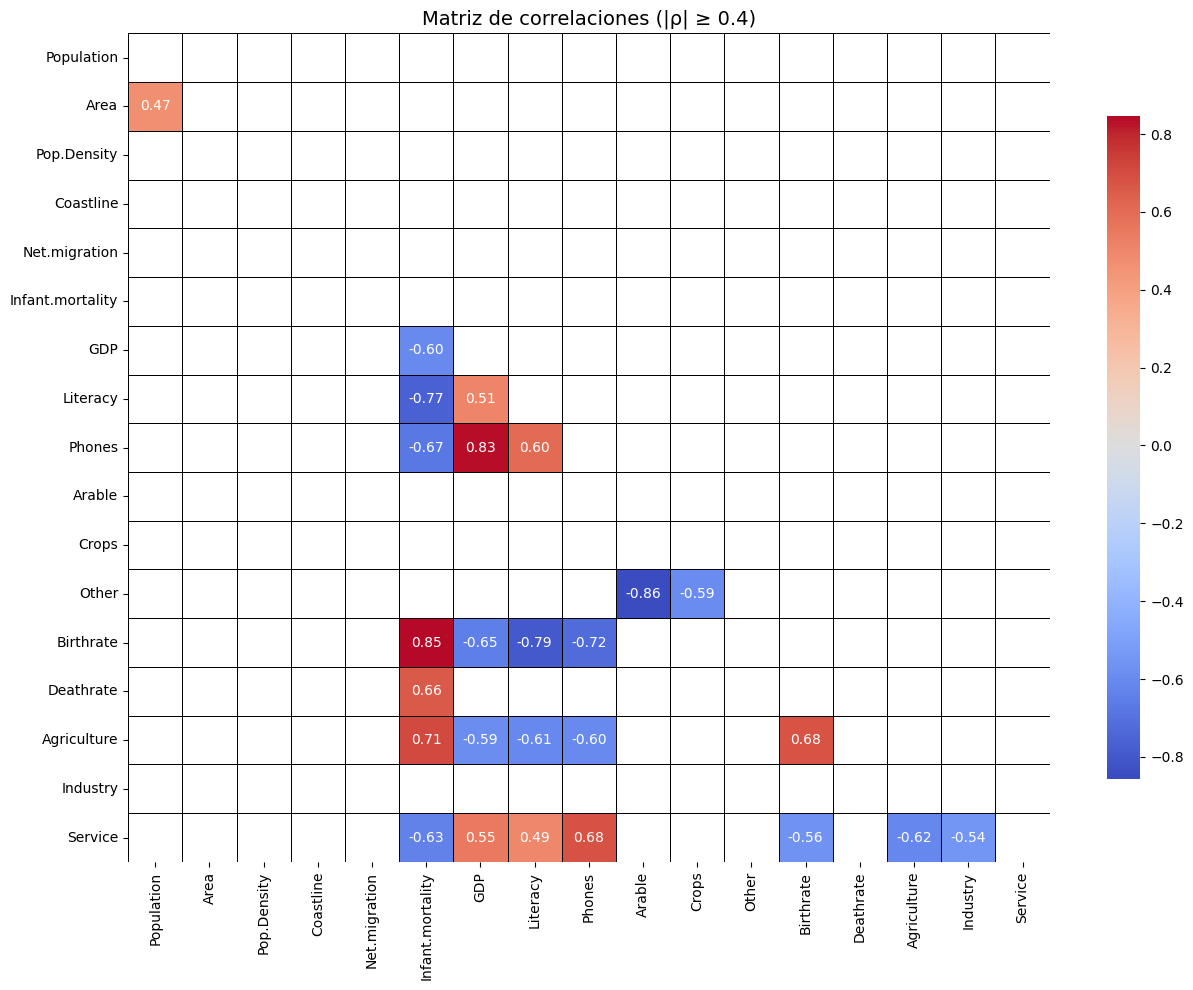

In [64]:
# Umbral de correlación
threshold = 0.4

# Copia de la matriz de correlaciones
corr_filtered = corr_matrix.copy()

# Anular correlaciones por debajo del umbral
corr_filtered[abs(corr_filtered) < threshold] = np.nan

# Máscara para triángulo superior
mask = np.triu(np.ones_like(corr_filtered, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_filtered,
    mask=mask,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor="black",
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de correlaciones (|ρ| ≥ 0.4)", fontsize=14)
plt.tight_layout()
plt.show()



##### A.3.1.3. Diagrama de dispersión por pares

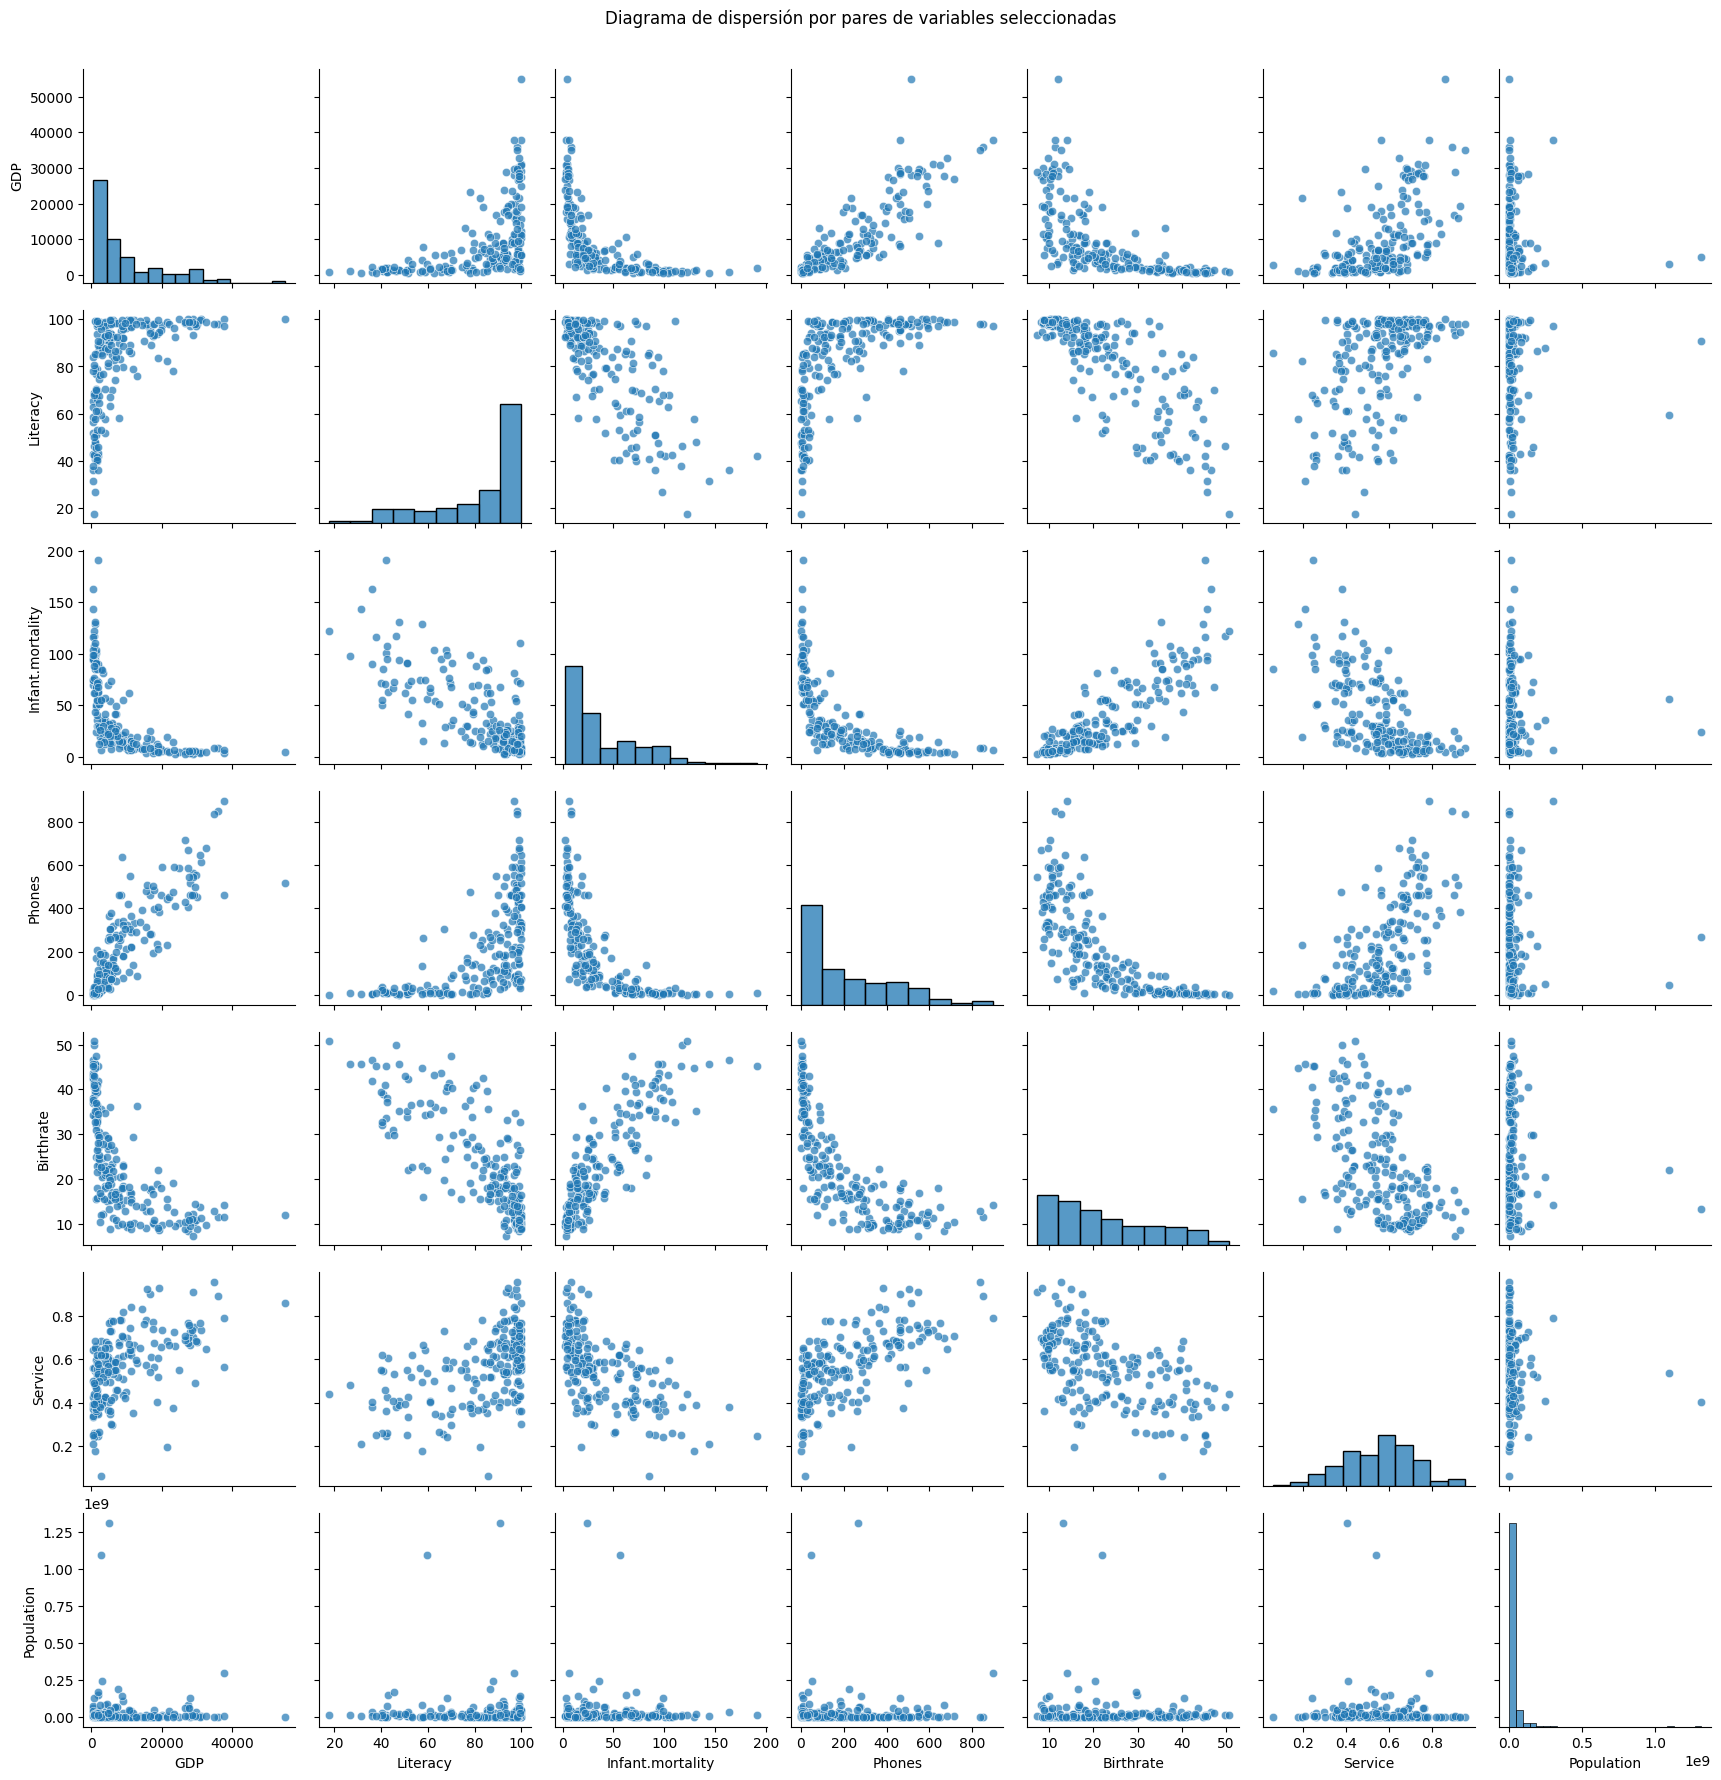

In [65]:
# Subconjunto de variables seleccionadas para el pairplot
pairplot_vars = [
    "GDP",
    "Literacy",
    "Infant.mortality",
    "Phones",
    "Birthrate",
    "Service",
    "Population"
]

pairplot_data = data_gdp[pairplot_vars].dropna()

# Pairplot
sns.pairplot(
    pairplot_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.7}
)

plt.suptitle(
    "Diagrama de dispersión por pares de variables seleccionadas",
    y=1.02
)
plt.show()


#### A.3.2. Análisis bivariante de variables categóricas

Con el objetivo de explorar posibles diferencias en el nivel de GDP entre distintos grupos de países, se analiza la relación entre el GDP y las variables categóricas `Region` y `Climate`. Para ello, se utilizan diagramas de caja que permiten comparar la distribución del GDP entre categorías.

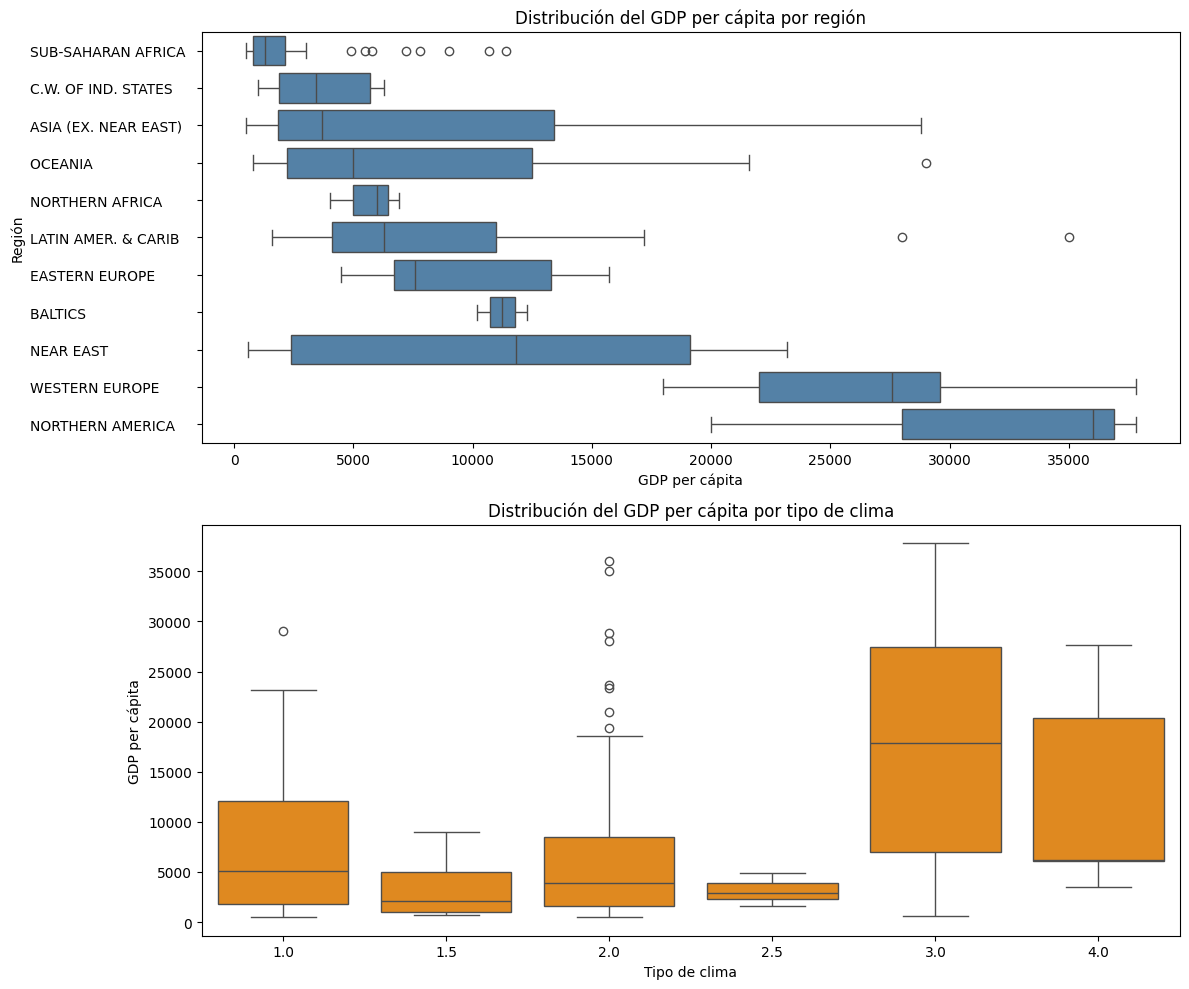

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

df_box = data_gdp[["GDP", "Region", "Climate"]].dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# =========================
# 1) GDP por REGIÓN (ordenado por mediana)
# =========================
order_region = (
    df_box.groupby("Region")["GDP"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df_box,
    x="GDP",
    y="Region",
    order=order_region,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Distribución del GDP per cápita por región")
axes[0].set_xlabel("GDP per cápita")
axes[0].set_ylabel("Región")


axes[0].tick_params(axis="y", pad=120)


for label in axes[0].get_yticklabels():
    label.set_horizontalalignment("left")
# ---------------------------

# =========================
# 2) GDP por CLIMA (Climate como categórica)
# =========================
order_climate = sorted(df_box["Climate"].unique())

sns.boxplot(
    data=df_box,
    x="Climate",
    y="GDP",
    order=order_climate,
    ax=axes[1],
    color="darkorange"
)
axes[1].set_title("Distribución del GDP per cápita por tipo de clima")
axes[1].set_xlabel("Tipo de clima")
axes[1].set_ylabel("GDP per cápita")

plt.tight_layout()
plt.show()

Los datos revelan una marcada desigualdad geográfica, donde **Norteamérica y Europa Occidental** lideran con **ingresos muy superiores**, mientras que África Subsahariana se concentra en el extremo inferior con poca dispersión. Por otro lado, la variable climática muestra una correlación visible: los climas categorizados como 3.0 y 4.0 presentan medianas de PIB per cápita significativamente más altas que los climas con índices menores (1.0 - 2.5).

## B. (1) Algunas variables tienen valores perdidos, trátalos de manera razonada y explícalo.


El conjunto de datos presenta valores perdidos en varias variables explicativas. Dado que el tamaño muestral es limitado y que las variables afectadas son relevantes para el análisis del PIB per cápita, se descarta la eliminación directa de observaciones como estrategia principal.

En el caso del resto de variables continuas con valores perdidos, se aplica una **imputación por la mediana calculada dentro de cada región**. Esta decisión se justifica por la existencia de diferencias estructurales entre regiones en términos de desarrollo económico, demográfico y social. La utilización de la mediana regional permite preservar dichas diferencias y reduce la influencia de valores extremos, manteniendo al mismo tiempo el tamaño muestral del conjunto de datos.

Dado el carácter categórico y altamente agregado de la variable `Climate`, y el reducido número de valores perdidos, estos se imputan utilizando la categoría climática más frecuente dentro de cada región. Esta estrategia permite una imputación objetiva y reproducible, coherente con la estructura regional del conjunto de datos. La coherencia de las imputaciones se verifica de forma general utilizando la [CIA World Factbook](https://www.cia.gov/the-world-factbook/) como referencia externa.

Antes de proceder a la estimación de los modelos de regresión, es necesario realizar un preprocesado adecuado del conjunto de datos con el fin de garantizar su calidad y coherencia interna. En este apartado se aborda, en primer lugar, el tratamiento de los valores perdidos presentes en varias variables del conjunto de datos.

Adicionalmente, el dataset incluye variables de naturaleza composicional, cuyas componentes están sujetas a restricciones de suma. En concreto, la distribución sectorial de la economía (`Agriculture`, `Industry` y `Service`) debe sumar 1, y la distribución del uso del suelo (`Arable`, `Crops` y `Other`) debe sumar 100. Dado que la imputación de valores perdidos se ha realizado de forma independiente por variable, estas restricciones pueden dejar de cumplirse exactamente. Por ello, se incorpora un proceso de verificación y normalización que restablece dichas identidades, asegurando la coherencia interna del conjunto de datos antes del análisis de regresión.

---




### B.1. Imputación por mediana dentro de cada región (excepto `Climate` y `GDP`)

#### B.1.1 Valores perdidos por región y variable

In [67]:


# Variables numéricas excluyendo Climate y GDP
num_cols = data_gdp.select_dtypes(include=["int64", "float64"]).columns.tolist()
cols_to_impute = [c for c in num_cols if c not in ["Climate", "GDP"]]

# Conteo de valores perdidos por región y variable
missing_by_region = (
    data_gdp
    .groupby("Region")[cols_to_impute]
    .apply(lambda x: x.isna().sum())
)

# Columna: total de valores perdidos por región
missing_by_region["Total_missing_region"] = missing_by_region.sum(axis=1)

# Fila: total de valores perdidos por variable
missing_by_region.loc["Total_missing_variable"] = missing_by_region.sum(axis=0)

missing_by_region


,Population,Area,Pop.Density,Coastline,Net.migration,Infant.mortality,Literacy,Phones,Arable,Crops,Other,Birthrate,Deathrate,Agriculture,Industry,Service,Total_missing_region
Region,,,,,,,,,,,,,,,,,
ASIA (EX. NEAR EAST),0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
BALTICS,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
C.W. OF IND. STATES,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
EASTERN EUROPE,0,0,0,0,0,0,3,0,0,0,0,1,1,0,0,0,5
LATIN AMER. & CARIB,0,0,0,0,0,0,1,1,0,0,0,0,0,2,2,2,8
NEAR EAST,0,0,0,0,0,0,2,1,0,0,0,0,0,0,0,0,3
NORTHERN AFRICA,0,0,0,0,1,1,1,1,0,0,0,1,1,1,1,0,8
NORTHERN AMERICA,0,0,0,0,0,0,1,0,0,0,0,0,0,2,2,2,7
OCEANIA,0,0,0,0,2,2,4,0,0,0,0,1,2,5,5,5,26


**Interpretación de los valores perdidos por región y variable**

El análisis de los valores perdidos por región y variable muestra que los valores faltantes no se concentran de forma exclusiva en una única región ni en una sola variable, sino que se distribuyen de manera heterogénea entre regiones y variables explicativas.

Se observa que algunas variables, como `Literacy`, `Industry` o `Service`, presentan un mayor número de valores perdidos a nivel global, mientras que otras muestran una cobertura prácticamente completa. Asimismo, existen regiones con un mayor número total de valores faltantes, lo que sugiere diferencias en la disponibilidad de información entre áreas geográficas.

Este patrón refuerza la conveniencia de aplicar una **estrategia de imputación diferenciada por región**, ya que permite preservar las diferencias estructurales entre regiones y evitar el uso de valores globales que podrían distorsionar el análisis posterior.

---


#### B.1.2 Cálculo de mediana de cada variable por región

In [68]:

median_by_region = (
    data_gdp
    .groupby("Region")[cols_to_impute]
    .median()
)

median_by_region


,Population,Area,Pop.Density,Coastline,Net.migration,Infant.mortality,Literacy,Phones,Arable,Crops,Other,Birthrate,Deathrate,Agriculture,Industry,Service
Region,,,,,,,,,,,,,,,,
ASIA (EX. NEAR EAST),26336502.5,208920.0,192.00,1.235,0.000,30.775,90.60,61.50,13.595,1.005,81.160,19.565,6.960,0.1610,0.2815,0.4950
BALTICS,2274735.0,64589.0,35.20,0.820,-2.230,7.870,99.80,321.40,29.670,0.470,69.860,9.240,13.250,0.0400,0.2940,0.6660
C.W. OF IND. STATES,7641217.0,203050.0,56.10,0.000,-2.085,32.425,99.05,155.35,11.135,0.875,86.520,15.850,9.325,0.1980,0.3295,0.4595
EASTERN EUROPE,6412407.5,67704.0,102.75,0.065,0.085,9.330,98.60,296.05,31.755,2.260,65.335,9.720,10.310,0.0815,0.3095,0.5910
LATIN AMER. & CARIB,1065842.0,22966.0,91.40,3.370,-1.220,18.050,94.05,222.85,7.600,1.980,87.230,18.020,6.090,0.0700,0.2590,0.6180
NEAR EAST,3488139.5,51825.0,87.50,1.145,0.555,19.060,83.00,211.00,5.305,2.780,89.660,21.595,4.560,0.0350,0.3520,0.5840
NORTHERN AFRICA,21552552.5,724000.0,38.00,0.325,-0.390,31.000,70.00,123.60,3.045,0.365,96.590,21.980,5.130,0.1320,0.3570,0.4255
NORTHERN AMERICA,65773.0,2166086.0,29.00,2.040,2.490,7.540,97.50,683.20,13.040,0.000,86.960,13.520,7.800,0.0100,0.2040,0.7870
OCEANIA,114689.0,811.0,60.10,47.080,0.000,12.620,95.00,118.60,5.710,6.990,84.400,22.320,5.690,0.1505,0.1710,0.6440


#### B.1.3 Imputación de valores perdidos por mediana regional

In [69]:

# Copia del dataframe para aplicar la imputación
data_gdp_imp = data_gdp.copy()

# Variables numéricas a imputar (excluyendo Climate y GDP)
num_cols = data_gdp_imp.select_dtypes(include=["int64", "float64"]).columns.tolist()
cols_to_impute = [c for c in num_cols if c not in ["Climate", "GDP"]]

# Imputación por mediana dentro de cada región
for col in cols_to_impute:
    data_gdp_imp[col] = data_gdp_imp[col].fillna(
        data_gdp_imp.groupby("Region")[col].transform("median")
    )

# Comprobación de valores perdidos restantes (excepto Climate)
remaining_missing = data_gdp_imp[cols_to_impute].isna().sum()
remaining_missing[remaining_missing > 0]


Series([], dtype: int64)

### B.2. Imputación de valores faltantes en `Climate` mediante la moda

#### B.2.1. Paises con valores faltantes en la variable `Climate`

In [70]:

# Filas con valores perdidos en Climate
countries_missing_climate = (
    data_gdp_imp.loc[data_gdp_imp["Climate"].isna(), ["Country", "Region"]]
    .sort_values("Region")
)

countries_missing_climate


,Country,Region
145,Nepal,ASIA (EX. NEAR EAST)
120,Lithuania,BALTICS
169,Russia,C.W. OF IND. STATES
137,Moldova,C.W. OF IND. STATES
50,Croatia,EASTERN EUROPE
181,Serbia,EASTERN EUROPE
186,Slovenia,EASTERN EUROPE
115,Lebanon,NEAR EAST
118,Libya,NORTHERN AFRICA
141,Morocco,NORTHERN AFRICA


#### B.2.2 Cálculo de la moda de `Climate` por región (ignorando NAs)

In [71]:

# Moda por región (en caso de empate, se toma la primera moda)
climate_mode_by_region = (
    data_gdp_imp
    .groupby("Region")["Climate"]
    .apply(lambda s: s.dropna().mode().iloc[0] if not s.dropna().mode().empty else np.nan)
)

climate_mode_by_region


Region
ASIA (EX. NEAR EAST)                   2.0
BALTICS                                3.0
C.W. OF IND. STATES                    1.0
EASTERN EUROPE                         3.0
LATIN AMER. & CARIB                    2.0
NEAR EAST                              1.0
NORTHERN AFRICA                        1.0
NORTHERN AMERICA                       1.0
OCEANIA                                2.0
SUB-SAHARAN AFRICA                     2.0
WESTERN EUROPE                         3.0
Name: Climate, dtype: float64

#### B.2.3 Imputación de `Climate` por moda regional

In [72]:

# Imputación: asignar a cada país con NA el valor de la moda de su región
data_gdp_imp["Climate"] = data_gdp_imp["Climate"].fillna(
    data_gdp_imp["Region"].map(climate_mode_by_region)
)

# Comprobación final
data_gdp_imp["Climate"].isna().sum()


np.int64(0)

### B.3. Normalizar sector económico y Normalizar uso del suelo


Una vez finalizado el tratamiento de los valores perdidos, se procede a verificar que las variables composicionales del conjunto de datos siguen cumpliendo sus restricciones de suma. Esta comprobación resulta necesaria, ya que la imputación se ha realizado de manera independiente para cada variable y puede alterar identidades exactas entre componentes.

In [73]:
# tolerancias
tol_sector = 1e-6
tol_land = 1e-6

sector_sum = data_gdp_imp[["Agriculture", "Industry", "Service"]].sum(axis=1)
land_sum   = data_gdp_imp[["Arable", "Crops", "Other"]].sum(axis=1)

bad_sector = (sector_sum - 1).abs() > tol_sector
bad_land   = (land_sum - 100).abs() > tol_land

print("Filas que NO cumplen sector (≈1):", bad_sector.sum())
print("Filas que NO cumplen suelo (≈100):", bad_land.sum())

Filas que NO cumplen sector (≈1): 58
Filas que NO cumplen suelo (≈100): 7



En esta celda se evalúa cuántas observaciones **NO** cumplen las restricciones de suma establecidas para las variables composicionales. En concreto, se comprueba si la suma de `Agriculture`, `Industry` y `Service` es aproximadamente igual a 1, y si la suma de `Arable`, `Crops` y `Other` es aproximadamente igual a 100.

El output muestra que un número significativo de observaciones no cumple estas identidades, lo que confirma que la imputación de valores perdidos ha introducido desviaciones en las variables composicionales y justifica la necesidad de aplicar un proceso de normalización.


#### B.3.1. Normalización de las variables del sector económico

In [74]:


sector_cols = ["Agriculture", "Industry", "Service"]

sector_sum = data_gdp_imp[sector_cols].sum(axis=1)

# Normalización fila a fila (evitando división por cero)
mask = sector_sum > 0
data_gdp_imp.loc[mask, sector_cols] = (
    data_gdp_imp.loc[mask, sector_cols]
    .div(sector_sum[mask], axis=0)
)


#### B.3.2. Normalización de las variables del uso del suelo

In [75]:


land_cols = ["Arable", "Crops", "Other"]

land_sum = data_gdp_imp[land_cols].sum(axis=1)

mask = land_sum > 0
data_gdp_imp.loc[mask, land_cols] = (
    data_gdp_imp.loc[mask, land_cols]
    .mul(100 / land_sum[mask], axis=0)
)

#### B.3.3 Verificación estadística tras la normalización

In [76]:
tol = 1e-6

sector_check = (data_gdp_imp[sector_cols].sum(axis=1) - 1).abs() > tol
land_check   = (data_gdp_imp[land_cols].sum(axis=1) - 100).abs() > tol

print("Filas que NO cumplen sector:", sector_check.sum())
print("Filas que NO cumplen suelo:", land_check.sum())


Filas que NO cumplen sector: 0
Filas que NO cumplen suelo: 0


In [77]:

# DataFrame auxiliar con las sumas
check_df = pd.DataFrame({
    "Sector_sum": data_gdp_imp[["Agriculture", "Industry", "Service"]].sum(axis=1),
    "Land_use_sum": data_gdp_imp[["Arable", "Crops", "Other"]].sum(axis=1)
})

check_df.describe()


,Sector_sum,Land_use_sum
count,2.270000e+02,2.270000e+02
mean,1.000000e+00,1.000000e+02
std,3.765674e-17,1.336845e-15
min,1.000000e+00,1.000000e+02
25%,1.000000e+00,1.000000e+02
50%,1.000000e+00,1.000000e+02
75%,1.000000e+00,1.000000e+02
max,1.000000e+00,1.000000e+02



El output muestra que la media, el mínimo y el máximo de las sumas coinciden exactamente con los valores teóricos esperados (1 y 100, respectivamente), y que la desviación estándar es prácticamente nula. Cualquier pequeña discrepancia observada se debe únicamente a errores de precisión numérica.

Con la verificación y normalización de las variables composicionales, el conjunto de datos queda internamente coherente y completamente preparado para abordar las siguientes etapas del análisis, como la transformación de variables y la estimación de los modelos de regresión.

---

Finalmente, se elimina la observación con valor faltante en la variable objetivo `GDP`. Dado que `GDP` es la variable a explicar en el modelo de regresión, su imputación requeriría asumir un valor basado en la información de otras variables, lo que introduciría un componente artificial en el análisis y podría sesgar los resultados del modelo. Además, el número de observaciones afectadas es mínimo, por lo que la eliminación de esta fila no tiene un impacto relevante sobre el tamaño muestral ni sobre la representatividad del conjunto de datos.


In [78]:
data_gdp_imp = data_gdp_imp.dropna(subset=["GDP"])

## C. (0.5) Extra. Realiza las transformaciones de variables que consideres necesarias.


Antes de estimar los modelos de regresión, se evalúa la conveniencia de aplicar transformaciones a algunas variables del conjunto de datos. El objetivo de estas transformaciones es mejorar el ajuste del modelo y aproximar los datos a los supuestos de la regresión lineal, en particular la linealidad de las relaciones, la homocedasticidad de los errores y la estabilidad de las distribuciones.

Las transformaciones de las variables continuas se deciden a partir del análisis exploratorio univariante, prestando especial atención a la presencia de asimetría, colas largas y valores extremos. Este enfoque permite mejorar las propiedades estadísticas de las variables antes de la estimación del modelo, sin introducir complejidad innecesaria en la interpretación de los coeficientes.

La decisión de transformar una variable se basa en el análisis exploratorio previo y se aplica de forma selectiva, evitando transformaciones innecesarias cuando la relación en niveles resulta adecuada.


### C.1. Transformación logarítmica de `GDP`

La variable `GDP` presenta una distribución fuertemente asimétrica y relaciones no lineales con varias variables explicativas. Por ello, se aplica una transformación logarítmica con el objetivo de reducir la asimetría, estabilizar la varianza y mejorar la linealidad de las relaciones. Esta transformación facilita además una interpretación económica más clara de los coeficientes del modelo.

In [79]:
data_gdp_imp["log_GDP"] = np.log(data_gdp_imp["GDP"])

In [80]:
# Comparación de estadísticos descriptivos
data_gdp_imp[["GDP", "log_GDP"]].describe()

,GDP,log_GDP
count,226.000000,226.000000
mean,9689.823009,8.566462
std,10049.138513,1.197826
min,500.000000,6.214608
25%,1900.000000,7.549609
50%,5550.000000,8.621513
75%,15700.000000,9.661416
max,55100.000000,10.916905


La comparación de los estadísticos descriptivos de `GDP` y `log(GDP)` confirma que la transformación logarítmica mejora sustancialmente las propiedades estadísticas de la variable objetivo. En particular, la asimetría se reduce de forma notable, la dispersión relativa disminuye y la diferencia entre media y mediana se atenúa. Estos resultados refuerzan la conveniencia de utilizar `log(GDP)` como variable dependiente en los modelos de regresión posteriores.

Ahora se crea un scatterplot entre `log(GDP)` y el resto de variables:

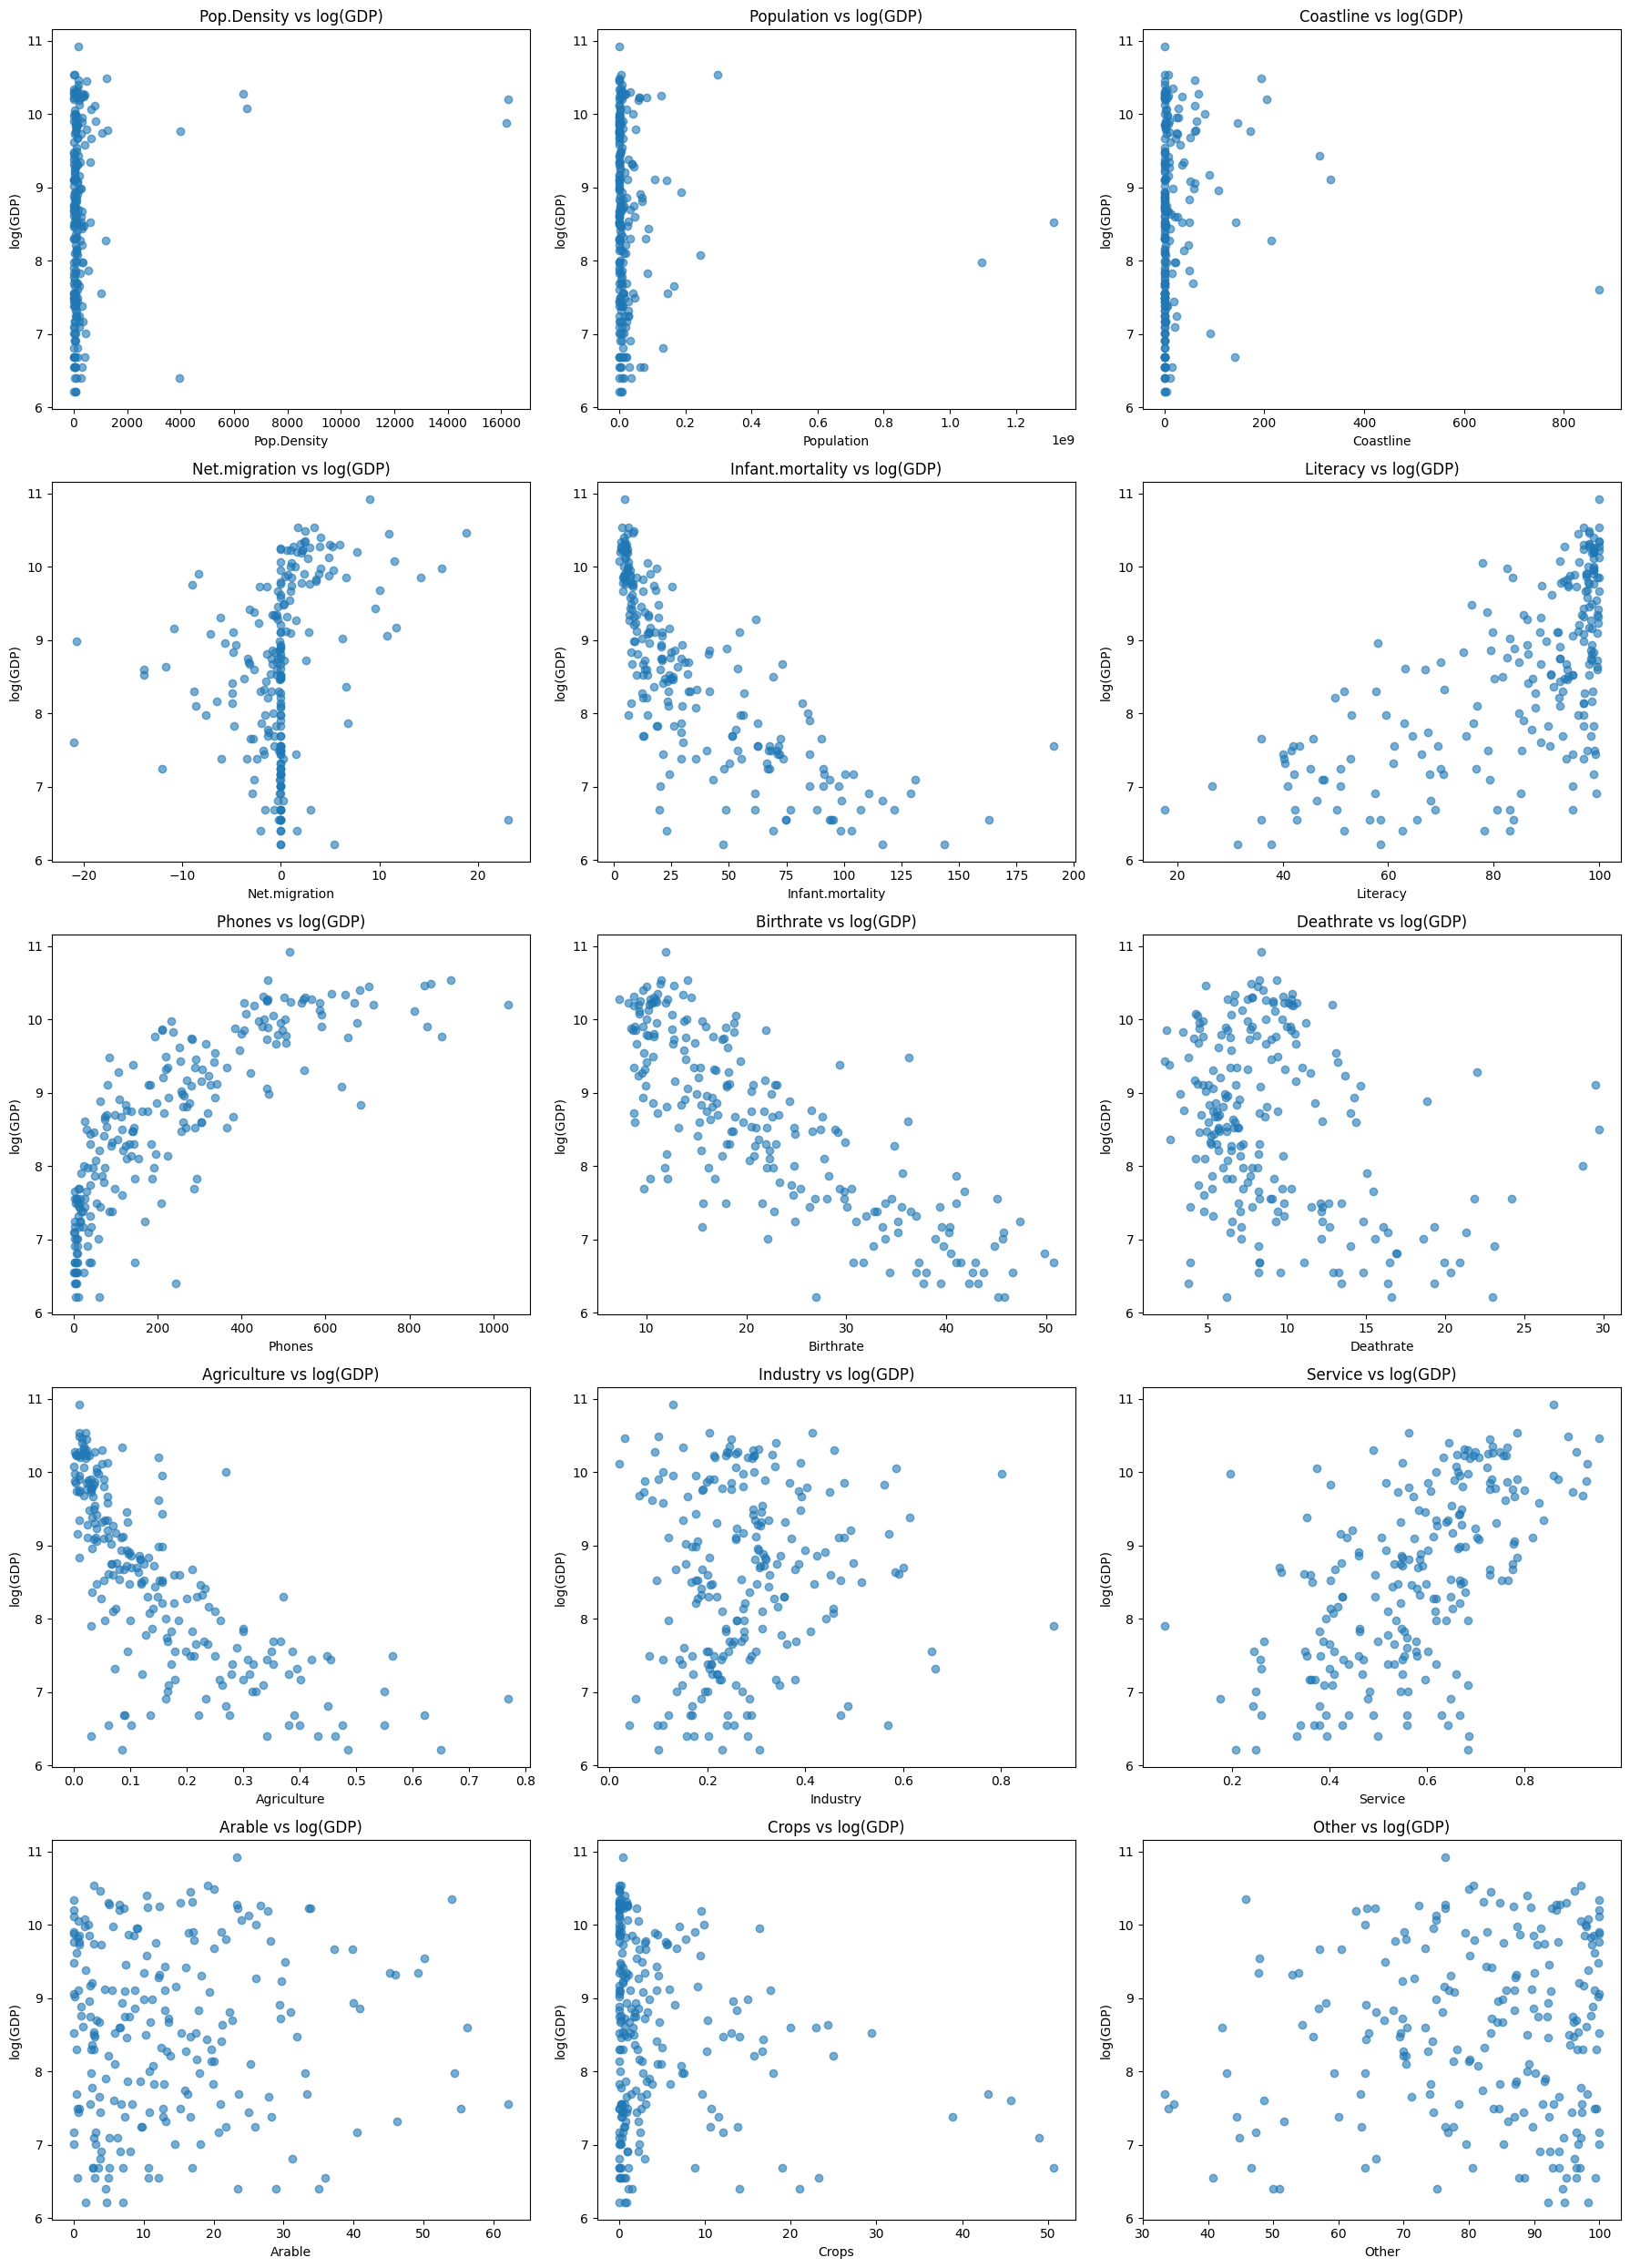

In [81]:

vars_x = [
    "Pop.Density",
    "Population",
    "Coastline",
    "Net.migration",
    "Infant.mortality",
    "Literacy",
    "Phones",
    "Birthrate",
    "Deathrate",
    "Agriculture",
    "Industry",
    "Service",
    "Arable",
    "Crops",
    "Other"
]

n_cols = 3
n_rows = int(np.ceil(len(vars_x) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, var in enumerate(vars_x):
    axes[i].scatter(
        data_gdp_imp[var],
        data_gdp_imp["log_GDP"],
        alpha=0.6
    )
    axes[i].set_xlabel(var)
    axes[i].set_ylabel("log(GDP)")
    axes[i].set_title(f"{var} vs log(GDP)")

# Eliminar ejes vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()




La decisión de transformar una variable no debe responder a un criterio automático ni puramente técnico, sino a una combinación razonada de evidencia empírica y coherencia teórica. En este trabajo, la selección de transformaciones se basa en los siguientes principios, aplicados de forma jerárquica:

1. **Relación con la variable objetivo**  
   Solo se consideran transformaciones para aquellas variables que muestran una relación clara y estructurada con la variable objetivo `log(GDP)`. Si el diagrama de dispersión no revela ningún patrón interpretable (lineal o no lineal), la transformación no se justifica, ya que no puede crear información donde no la hay.

2. **Sentido socioeconómico de la transformación**  
   Toda transformación implica asumir una forma funcional concreta (por ejemplo, rendimientos decrecientes o efectos proporcionales). Por ello, únicamente se aplican transformaciones que puedan justificarse desde un punto de vista económico o social, y cuya interpretación sea defendible en el contexto del análisis.

3. **Evidencia del análisis univariante**  
   El análisis de la distribución de cada variable (asimetría, colas largas, presencia de valores extremos) se utiliza como criterio complementario. Una distribución fuertemente asimétrica puede reforzar la conveniencia de una transformación, pero nunca constituye por sí sola un motivo suficiente para aplicarla.

Este enfoque evita transformaciones arbitrarias o motivadas únicamente por mejoras formales del ajuste del modelo, priorizando en su lugar la interpretabilidad, la coherencia económica y la robustez del análisis.

---

### C.2. Transformación del resto de variables

#### C.2.1. Transformación logarítmica de `Infant.mortality`


La variable `Infant.mortality` presenta una relación clara, negativa y no lineal con la variable objetivo `log(GDP)`, tal y como se observa en el análisis gráfico. En particular, se identifica un patrón de **rendimientos decrecientes**, donde reducciones iniciales en la mortalidad infantil se asocian a incrementos relativamente mayores del PIB per cápita, mientras que mejoras adicionales en niveles ya bajos tienen un impacto marginal menor.

Desde el punto de vista estadístico, la variable muestra además una **distribución fuertemente asimétrica**, con una cola larga hacia valores elevados, lo que refuerza la conveniencia de aplicar una transformación que reduzca la asimetría y estabilice la varianza.

Entre las posibles transformaciones, se opta por una **transformación logarítmica** por los siguientes motivos:
- Permite linealizar de forma suave la relación con `log(GDP)`, sin sobrerrepresentar los valores más bajos.
- Facilita una interpretación económica clara en términos de cambios proporcionales.

Se descartan transformaciones más agresivas, como la inversa, al introducir una ponderación excesiva de los valores más bajos y dificultar tanto la estabilidad del modelo como la interpretación de los coeficientes.

En consecuencia, se emplea `log(Infant.mortality)` como variable explicativa transformada en los modelos posteriores.


In [82]:
data_gdp_imp["log_Infant_mortality"] = np.log(data_gdp_imp["Infant.mortality"])

#### C.2.2. Transformación logarítmica de `Phones`


La variable `Phones` (número de teléfonos por cada 1.000 habitantes) muestra una relación positiva clara y no lineal con la variable objetivo `log(GDP)`. El análisis gráfico revela un patrón de **rendimientos decrecientes**, en el que incrementos iniciales en el nivel de infraestructura de telecomunicaciones se asocian a aumentos relativamente mayores del PIB per cápita, mientras que en niveles elevados el efecto marginal se atenúa.

Desde el punto de vista estadístico, `Phones` presenta una **distribución fuertemente asimétrica**, con una cola larga hacia valores elevados, lo que sugiere la conveniencia de una transformación que reduzca la asimetría y estabilice la varianza.

La transformación logarítmica se considera adecuada en este contexto por los siguientes motivos:
- Permite aproximar una relación más lineal con `log(GDP)`.
- Reduce la influencia de valores extremos sin eliminar información relevante.
- Es consistente con una interpretación económica en términos de cambios proporcionales en el nivel de infraestructura tecnológica.

Por estos motivos, se emplea `log(Phones)` como variable explicativa transformada en los modelos posteriores, manteniéndose el resto de variables demográficas en niveles.


In [83]:
data_gdp_imp["log_Phones"] = np.log(data_gdp_imp["Phones"])

## D. (2.25) Utiliza la metodología Best Subset Subselection para seleccionar las características para ajustar un modelo de regresión lineal para predecir la variable GDP.

Las variables `Region` y `Climate` se han excluido del modelo al representar características geográficas estructurales no modificables, cuya inclusión dificultaría la interpretación del modelo en términos de recomendaciones económicas realistas para aumentar el PIB per cápita (apartado J).

In [84]:
# Variable objetivo
y = data_gdp_imp["log_GDP"]

# Variables explicativas candidatas
features = [
    "log_Infant_mortality",
    "log_Phones",
    "Net.migration",
    "Agriculture",
    "Crops",
    "Deathrate"
]

X = data_gdp_imp[features]

In [85]:
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from itertools import combinations
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.regressionplots import influence_plot
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

def best_subset_selection(X, y, max_features=None, metric='adj_r2', method='best'):
    if max_features is None:
        max_features = len(X.columns)
    n = len(y)
    resultados = []

    def get_metrics(X_subset, y):
        X_sm = sm.add_constant(X_subset)
        model_sm = sm.OLS(y, X_sm).fit()
        y_pred = model_sm.predict(X_sm)
        mse = mean_squared_error(y, y_pred)
        r2 = r2_score(y, y_pred)
        p = X_subset.shape[1]
        adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
        aic = model_sm.aic
        bic = model_sm.bic
        return mse, r2, adj_r2, aic, bic, model_sm

    if method == 'best':
        for k in range(1, max_features + 1):
            for combo in combinations(X.columns, k):
                X_subset = X[list(combo)]
                mse, r2, adj_r2, aic, bic, model_sm = get_metrics(X_subset, y)
                resultados.append({'features': combo, 'mse': mse, 'r2': r2, 'adj_r2': adj_r2,
                                  'aic': aic, 'bic': bic, 'model': model_sm})
    elif method == 'forward':
        import copy
        remaining_features = list(X.columns)
        selected_features = []
        for k in range(1, max_features + 1):
            scores = []
            for feature in remaining_features:
                current_features = selected_features + [feature]
                X_subset = X[current_features]
                mse, r2, adj_r2, aic, bic, model_sm = get_metrics(X_subset, y)
                if metric == 'aic': score = aic
                elif metric == 'bic': score = bic
                elif metric == 'mse': score = mse
                elif metric == 'r2': score = r2
                else: score = adj_r2
                scores.append({'features': copy.deepcopy(current_features), 'score': score,
                              'mse': mse, 'r2': r2, 'adj_r2': adj_r2, 'aic': aic, 'bic': bic,
                              'model': model_sm})
            # Escoger el mejor
            reverse = metric in ['r2','adj_r2']
            scores = sorted(scores, key=lambda x: x['score'], reverse=reverse)
            # Añadir mejor
            selected_features = scores[0]['features']
            remaining_features.remove(scores[0]['features'][-1])
            resultados.append(scores[0])
    elif method == 'backward':
        selected_features = list(X.columns)
        while len(selected_features) > max_features:
            scores = []
            for feature in selected_features:
                current_features = [f for f in selected_features if f != feature]
                X_subset = X[current_features]
                mse, r2, adj_r2, aic, bic, model_sm = get_metrics(X_subset, y)
                if metric == 'aic': score = aic
                elif metric == 'bic': score = bic
                elif metric == 'mse': score = mse
                elif metric == 'r2': score = r2
                else: score = adj_r2
                scores.append({'features': current_features, 'score': score,
                              'mse': mse, 'r2': r2, 'adj_r2': adj_r2, 'aic': aic, 'bic': bic,
                              'model': model_sm})
            # Escoger el mejor
            reverse = metric in ['r2','adj_r2']
            scores = sorted(scores, key=lambda x: x['score'], reverse=reverse)
            selected_features = scores[0]['features']
            resultados.append(scores[0])
        # Almacenar el último modelo (con max_features)
        X_subset = X[selected_features]
        mse, r2, adj_r2, aic, bic, model_sm = get_metrics(X_subset, y)
        resultados.append({'features': selected_features, 'mse': mse, 'r2': r2, 'adj_r2': adj_r2,
                           'aic': aic, 'bic': bic, 'model': model_sm})
    else:
        raise ValueError('Método no reconocido')

    # Ordenar el resultado final
    reverse_order = metric in ['r2', 'adj_r2']
    resultados = sorted(resultados, key=lambda x: x[metric], reverse=reverse_order)
    return resultados

In [86]:
# Ejecutar best subset selection y mostrar 5 mejores
metrica = 'adj_r2' # aic
best_subsets = best_subset_selection(X, y, max_features=6, method="best", metric = metrica)
for i, res in enumerate(best_subsets[:5]): 
    print(f"Modelo {i+1}: variables {res['features']} 	 {metrica}: ", res[f'{metrica}'])

Modelo 1: variables ('log_Infant_mortality', 'log_Phones', 'Net.migration', 'Agriculture', 'Crops', 'Deathrate') 	 adj_r2:  0.8237876125376316
Modelo 2: variables ('log_Infant_mortality', 'log_Phones', 'Agriculture', 'Crops', 'Deathrate') 	 adj_r2:  0.8212881006680038
Modelo 3: variables ('log_Infant_mortality', 'log_Phones', 'Net.migration', 'Agriculture', 'Crops') 	 adj_r2:  0.8174297770261942
Modelo 4: variables ('log_Infant_mortality', 'log_Phones', 'Net.migration', 'Crops', 'Deathrate') 	 adj_r2:  0.8153495290569668
Modelo 5: variables ('log_Infant_mortality', 'log_Phones', 'Agriculture', 'Crops') 	 adj_r2:  0.8147455170174382


---

Los resultados muestran que el modelo con mejor rendimiento según el coeficiente de determinación ajustado (Adjusted R²) incluye las variables  
`log_Infant_mortality`, `log_Phones`, `Net.migration`, `Agriculture`, `Crops` y `Deathrate`.  
Además, se observa que varias de estas variables —en particular `log_Infant_mortality`, `log_Phones`, `Agriculture` y `Crops`— aparecen de forma recurrente en los mejores subconjuntos, lo que indica que su relación con el PIB per cápita es **robusta** y no depende de una especificación concreta del modelo.

La exclusión de otras variables potencialmente relevantes, como `Literacy` o `Birthrate`, se explica por su elevada correlación con variables ya incluidas en el modelo, especialmente con `log_Infant_mortality` y `log_Phones`. En presencia de estas, dichas variables no aportan información adicional significativa y su inclusión no mejora el ajuste medido por el Adjusted R².

Por su parte, la variable `Population` tampoco es seleccionada, ya que mide el tamaño absoluto del país y no su nivel de desarrollo. Dado que el PIB per cápita es una variable intensiva, el tamaño poblacional no resulta determinante una vez controlados otros factores estructurales, además de dificultar la interpretación económica del modelo.

En consecuencia, la selección final de variables combina resultados cuantitativos con consideraciones económicas y de interpretabilidad, garantizando que el modelo resultante sea útil tanto para la predicción como para el análisis y la formulación de recomendaciones de política económica.

---

In [87]:
# Seleccionar mejores variables y ajustar modelo statsmodels
best_features = list(best_subsets[0]['features'])
X_best = sm.add_constant(X[best_features])
model = sm.OLS(y, X_best).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                log_GDP   R-squared:                       0.828
Model:                            OLS   Adj. R-squared:                  0.824
Method:                 Least Squares   F-statistic:                     176.3
Date:                Sun, 18 Jan 2026   Prob (F-statistic):           6.07e-81
Time:                        18:49:15   Log-Likelihood:                -161.74
No. Observations:                 226   AIC:                             337.5
Df Residuals:                     219   BIC:                             361.4
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    9.1454 

## E.(0.75) Estudia la existencia de outliers o high leverage points. Si lo crees necesario descarta observaciones argumentando.

### E.1. Ajustar el modelo final y guardar residuos


En esta celda se ajusta el modelo de regresión lineal final mediante mínimos cuadrados ordinarios (OLS), incorporando el término independiente. A partir del modelo estimado se obtienen los residuos y los valores ajustados.

Los **residuos** representan la diferencia entre los valores observados y los valores predichos por el modelo y constituyen la base para la detección de posibles *outliers*. Por su parte, los **valores ajustados** se utilizarán posteriormente en los análisis de diagnóstico del modelo y en la identificación de observaciones con alta influencia o alto *leverage*.

In [88]:
X_sm = sm.add_constant(X) 
model = sm.OLS(y, X_sm).fit()

residuals = model.resid
fitted = model.fittedvalues

### E.2 Detección de outliers mediante residuos studentizados



En esta celda se analizan posibles **outliers** a partir de los residuos del modelo. Para ello se utilizan los **residuos studentizados externos**, que estandarizan los residuos teniendo en cuenta la varianza estimada del modelo y la influencia de cada observación. Este tipo de residuo es especialmente adecuado para la detección de valores atípicos en regresión lineal.

Se consideran candidatos a outlier aquellas observaciones cuyo valor absoluto del residuo studentizado es superior a 3. Aplicando este umbral, se identifican tres observaciones que presentan errores inusualmente grandes respecto a lo predicho por el modelo.

En esta etapa dichas observaciones se señalan únicamente como **posibles outliers**, sin proceder todavía a su eliminación. Su impacto real sobre el modelo se evaluará posteriormente mediante medidas de influencia.


In [89]:
influence = model.get_influence()
studentized_residuals = influence.resid_studentized_external

In [90]:
outliers = np.where(np.abs(studentized_residuals) > 3)[0]
outliers

array([ 58,  74, 222])

El resultado obtenido indica que las observaciones con índices **58, 74 y 222** presentan valores absolutos de los residuos studentizados superiores al umbral establecido. Esto significa que, para estas observaciones, el error cometido por el modelo es considerablemente mayor que el observado en el resto de los datos.

No obstante, el hecho de que una observación sea identificada como outlier en términos de residuo **no implica necesariamente que deba ser eliminada**. Estas observaciones pueden corresponder a países con características reales particulares y, por tanto, su eliminación solo estaría justificada si además ejercen una influencia desproporcionada sobre el ajuste del modelo.

Por este motivo, en los siguientes pasos se analizará si estas observaciones presentan también **alto leverage** o una **distancia de Cook elevada**, con el fin de determinar si son realmente influyentes y si su exclusión está justificada.

### E.3. Detección de HIGH LEVERAGE POINTS


En esta celda se identifican posibles **high leverage points**, es decir, observaciones con valores extremos en las variables explicativas que pueden tener un peso elevado en la estimación del modelo.

Para ello se utilizan los **valores de leverage** (o *hat values*), extraídos de la matriz sombrero del modelo. Estas medidas cuantifican cuánto influye cada observación, a través de sus variables explicativas, en su propio valor ajustado.

Siguiendo un criterio habitual en regresión múltiple, se define como umbral de leverage:

$$
h_i > \frac{2(p+1)}{n}
$$

donde \( p \) es el número de variables explicativas del modelo y \( n \) el número total de observaciones.


In [91]:
leverage = influence.hat_matrix_diag

In [92]:
p = X.shape[1]
n = X.shape[0]
leverage_threshold = 2 * (p + 1) / n
leverage_threshold


0.061946902654867256

En este caso, el umbral de leverage obtenido es aproximadamente **0.062**, valor que sirve únicamente como referencia para identificar observaciones con leverage relativamente elevado dentro de la muestra.

In [93]:
high_leverage = np.where(leverage > leverage_threshold)[0]
high_leverage

array([  0,   3,   5,  26,  38,  45,  46,  81,  87, 108, 116, 117, 130,
       136, 166, 178, 188, 189, 194, 203])


Aquí se obtienen un conjunto de índices que corresponden a las observaciones cuyo leverage supera dicho umbral. Estas observaciones son **candidatas a high leverage points**, ya que presentan combinaciones de valores en las variables explicativas poco habituales.

No obstante, un valor elevado de leverage **no implica por sí mismo que una observación sea influyente ni que deba ser eliminada**. Por este motivo, en el siguiente paso se analizará si estas observaciones ejercen una influencia significativa sobre el ajuste del modelo mediante la distancia de Cook.

### E.4. ¿Qué puntos son influyentes?

#### E.4.1. Cook's distance

#### E.4.1.1. Identificación de observaciones influyentes mediante distancia de Cook

En esta celda se calcula la **distancia de Cook**, una medida que combina el tamaño del residuo y el leverage de cada observación para cuantificar cuánto cambia el modelo si dicha observación se elimina.

Se utiliza el umbral habitual $$ \frac{4}{n} $$ para marcar observaciones **potencialmente influyentes**. El array obtenido contiene los índices de las observaciones cuya distancia de Cook supera este valor, por lo que se consideran candidatas a revisión.

Este criterio se interpreta como una regla de cribado: no implica eliminar automáticamente observaciones, sino identificar puntos que conviene analizar visualmente y contrastar estimando el modelo con y sin ellos.


In [94]:
cooks_d = influence.cooks_distance[0]

In [95]:
cooks_threshold = 4 / n
influential = np.where(cooks_d > cooks_threshold)[0]
influential

array([  0,  37,  45,  46,  51,  58,  63,  74, 108, 117, 136, 166, 171,
       176, 188, 189, 222])

El resultado obtenido muestra el conjunto de **índices de las observaciones cuya distancia de Cook supera el umbral \(4/n\)**. Estas observaciones son, por tanto, **candidatas a ser influyentes**, ya que su eliminación podría producir cambios apreciables en los coeficientes estimados o en la calidad del ajuste del modelo.

No obstante, este criterio debe interpretarse como un **mecanismo de detección preliminar** y no como una regla automática de eliminación. En muestras relativamente grandes, como la utilizada en este estudio, es habitual que varias observaciones superen el umbral de referencia sin que ello implique necesariamente un problema grave en el modelo.

Por este motivo, en el siguiente paso se analizará el impacto real de las observaciones con mayor distancia de Cook mediante la comparación del modelo original con modelos alternativos en los que se excluyen dichas observaciones, con el fin de evaluar si ejercen una influencia sustancial sobre los resultados.


#### E.4.2 Visualización: leverage (hat) y Cook's distance

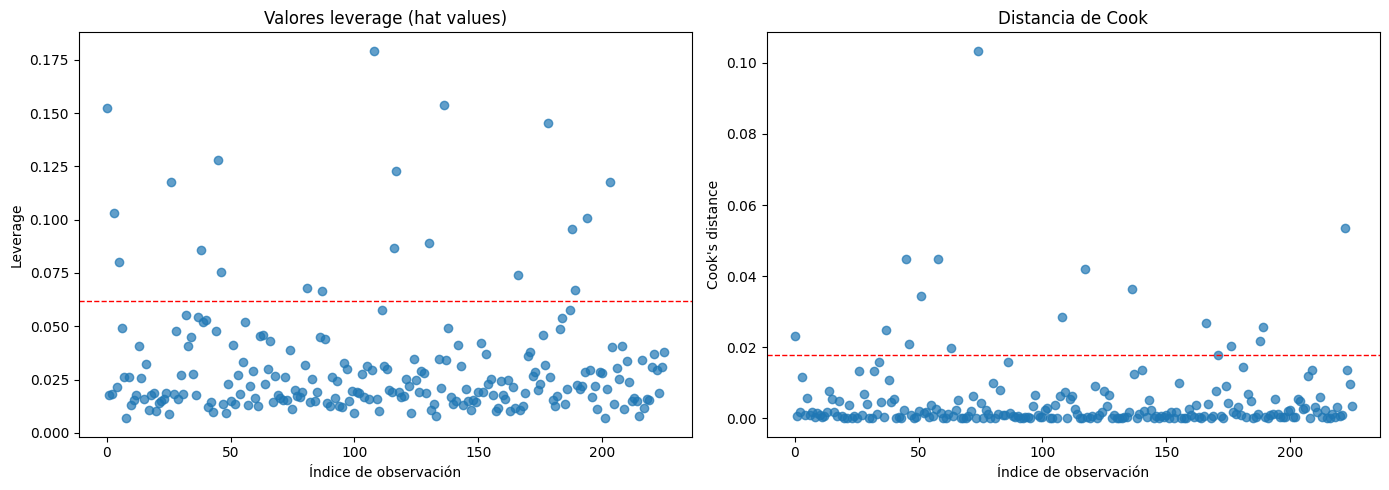

In [96]:

influence = model.get_influence()
hat_values = influence.hat_matrix_diag
cook_distance = influence.cooks_distance[0]

p = X.shape[1]
n = X.shape[0]

leverage_threshold = 2 * (p + 1) / n
cooks_threshold = 4 / n

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Hat values
axes[0].scatter(range(n), hat_values, alpha=0.7)
axes[0].axhline(leverage_threshold, color='red', linestyle="--", linewidth=1)
axes[0].set_title("Valores leverage (hat values)")
axes[0].set_xlabel("Índice de observación")
axes[0].set_ylabel("Leverage")

# Cook's distance
axes[1].scatter(range(n), cook_distance, alpha=0.7)
axes[1].axhline(cooks_threshold, color='red', linestyle="--", linewidth=1)
axes[1].set_title("Distancia de Cook")
axes[1].set_xlabel("Índice de observación")
axes[1].set_ylabel("Cook's distance")

plt.tight_layout()
plt.show()


Los gráficos de leverage (hat values) y de distancia de Cook permiten visualizar de forma conjunta la posible influencia de cada observación sobre el modelo.

En el gráfico de **leverage**, la mayoría de las observaciones presentan valores claramente inferiores al umbral teórico, lo que indica que, para la mayor parte de la muestra, las combinaciones de variables explicativas son representativas del conjunto de datos. No obstante, se observan algunas observaciones con valores de leverage superiores al umbral, que corresponden a países con perfiles explicativos poco habituales y que, por tanto, podrían tener un mayor peso en la estimación del modelo.

En el gráfico de **distancia de Cook**, la mayoría de las observaciones presentan valores muy reducidos, concentrados cerca de cero. Sin embargo, un número limitado de observaciones supera el umbral \(4/n\), lo que indica que su eliminación podría producir cambios apreciables en los coeficientes estimados o en las medidas de ajuste.

En conjunto, los gráficos confirman la presencia de algunas observaciones potencialmente influyentes. No obstante, la influencia debe evaluarse de manera individual, contrastando el modelo completo con modelos alternativos en los que se excluyen las observaciones con mayor distancia de Cook.

---


#### E.4.3 Criterio para la eliminación de observaciones influyentes

La identificación de observaciones con residuos elevados, alto leverage o distancia de Cook superior al umbral no implica automáticamente su eliminación del análisis. Siguiendo la práctica habitual en regresión lineal, una observación solo se considera verdaderamente influyente si su exclusión produce cambios relevantes en el modelo estimado.

En particular, para cada observación candidata se compara el modelo completo con un modelo alternativo en el que dicha observación es eliminada. Se evalúa si se producen cambios sustanciales en los coeficientes, en sus signos, en su significancia estadística o en las medidas de ajuste global del modelo.

Únicamente en el caso de que la eliminación de una observación altere de forma apreciable las conclusiones del modelo, se considera justificada su exclusión. En caso contrario, la observación se mantiene en el análisis al considerarse representativa de la heterogeneidad real de los datos.


Con el fin de evaluar la influencia real de las observaciones identificadas mediante la distancia de Cook, se estima un modelo alternativo en el que se excluye la observación con mayor valor de dicha medida. A continuación, se comparan los resultados del modelo completo y del modelo reducido para analizar si la exclusión de esta observación produce cambios sustanciales en los coeficientes estimados o en la calidad del ajuste.


In [97]:
idx = np.argmax(cooks_d) # Índice del punto más influyente

X_reduced = X_sm.drop(index=idx)
y_reduced = y.drop(index=idx)

model_reduced = sm.OLS(y_reduced, X_reduced).fit()

model.summary()
model_reduced.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                log_GDP   R-squared:                       0.840
Model:                            OLS   Adj. R-squared:                  0.836
Method:                 Least Squares   F-statistic:                     190.9
Date:                Sun, 18 Jan 2026   Prob (F-statistic):           7.06e-84
Time:                        18:49:16   Log-Likelihood:                -151.96
No. Observations:                 225   AIC:                             317.9
Df Residuals:                     218   BIC:                             341.8
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    9.0695      0.384     23.619      0.000       8.313       9.826
log_Infant_mortality    -0.5271      0.061     -8.707      0.000      -0.646      -0.408
log_Phones               0.2527      0.044      5.717      0.000       0.166       0.340
Net.migration            0.0180      0.007      2.475      0.014       0.004       0.032
Agriculture             -1.3595      0.358     -3.800      0.000      -2.065      -0.654
Crops                   -0.0151      0.004     -3.537      0.000      -0.024      -0.007
Deathrate                0.0229      0.008      2.923      0.004       0.007       0.038
==============================================================================
Omnibus:                       34.556   Durbin-Watson:                   1.933
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               51.484
Skew:                          -0.898   Prob(JB):                     6.61e-12
Kurtosis:                       4.505   Cond. No.                         170.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### E.4.5. Comparación modelo completo vs. modelo sin la observación más influyente (Cook)

Al excluir la observación con mayor distancia de Cook, el modelo pasa de **226** a **225** observaciones. La comparación entre ambos modelos muestra cambios apreciables en la bondad de ajuste:

- El **R²** aumenta de **0.828** a **0.840** y el **R² ajustado** de **0.824** a **0.836**.
- El **AIC** disminuye de **337.5** a **317.9** y el **BIC** de **361.4** a **341.8**, indicando un mejor ajuste penalizando la complejidad.
- Los coeficientes mantienen **los mismos signos** y continúan siendo estadísticamente significativos (p-valores < 0.05) en ambos modelos.
- Las magnitudes cambian de forma moderada (por ejemplo, `log_Infant_mortality` pasa de -0.550 a -0.527; `Agriculture` de -1.263 a -1.360), sin alterar la interpretación cualitativa del modelo.

En conjunto, la observación eliminada puede considerarse **influyente en términos de ajuste global** (mejora notable de AIC/BIC y R²), aunque **no altera las conclusiones principales** del modelo (signos y significancia se mantienen). Por ello, la decisión de excluirla solo estaría justificada si se considera que dicha observación es anómala o no representativa (p. ej., error de medición). En caso contrario, resulta razonable mantenerla para preservar la heterogeneidad real de los datos.


#### E.4.6. Presencia de valores influyentes

In [98]:
data_gdp_imp.loc[influential, "Country"] # Paises con observaciones influyentes

0               Afghanistan 
37               Cape Verde 
45         Congo, Dem. Rep. 
46     Congo, Repub. of the 
51                     Cuba 
58               East Timor 
63                  Eritrea 
74               Gaza Strip 
108                Kiribati 
117                 Liberia 
136    Micronesia, Fed. St. 
166                   Qatar 
171            Saint Helena 
176                   Samoa 
188                 Somalia 
189            South Africa 
222               West Bank 
Name: Country, dtype: object

El análisis de los valores de leverage revela que las observaciones identificadas como high leverage points corresponden mayoritariamente a países o territorios con características socioeconómicas extremas, tales como economías en conflicto (Afghanistan, Somalia, Gaza Strip, West Bank), microestados o economías insulares (Kiribati, Samoa, Micronesia, Saint Helena), países con muy bajo nivel de desarrollo (Liberia, East Timor, Eritrea) o economías altamente especializadas y de renta muy elevada (Qatar).

Estas observaciones presentan valores alejados en el espacio de las variables explicativas, lo que explica su elevado leverage, pero no constituyen errores de medición ni observaciones inconsistentes. Por el contrario, reflejan realidades económicas estructuralmente distintas que forman parte del fenómeno analizado.

Asimismo, la exclusión de estas observaciones no altera los signos, la significancia estadística ni la interpretación económica de los coeficientes estimados, lo que indica que su presencia no distorsiona las conclusiones del modelo, aunque sí influye en las medidas de ajuste global.

En consecuencia, y con el fin de preservar la heterogeneidad real de la muestra y evitar un sesgo hacia economías de características medias, se decide mantener estas observaciones en el modelo final, documentando su influencia pero sin proceder a su eliminación.

##### E.4.6.1. Identificación y descripción del punto más influyente

In [99]:
idx # Índice del punto más influyente

np.int64(74)

In [100]:
cooks_d[idx] # Valor de Cook's distance del punto más influyente

np.float64(0.10340729861970933)

In [101]:
cooks_threshold # Umbral de Cook's distance

0.017699115044247787

In [102]:
data_gdp_imp.loc[idx, "Country"] # País correspondiente al punto más influyente

'Gaza Strip '

In [103]:
data_gdp_imp.loc[idx, X.columns.tolist() + ["log_GDP"]] # Valores de las variables para el punto más influyente

log_Infant_mortality    3.132446
log_Phones              5.498397
Net.migration                1.6
Agriculture                 0.03
Crops                      21.05
Deathrate                    3.8
log_GDP                  6.39693
Name: 74, dtype: object

#### E.4.6.2. Conclusión sobre la presencia de observaciones influyentes

El análisis de residuos studentizados, valores de leverage y distancia de Cook identifica como observación más influyente a la correspondiente al índice 74, que se asocia al territorio de *Gaza Strip*. Dicha observación presenta una distancia de Cook de aproximadamente 0.103, valor notablemente superior al umbral teórico \(4/n\) (0.017), lo que confirma su carácter potencialmente influyente desde el punto de vista estadístico.

El examen de sus características socioeconómicas revela valores extremos en variables clave, como una elevada mortalidad infantil, un bajo nivel de acceso a telefonía y un reducido nivel de renta, lo que refleja una situación estructural excepcional. Estos valores no responden a un error de medición, sino a una realidad económica y social singular.

La comparación entre el modelo completo y un modelo alternativo en el que se excluye esta observación muestra una mejora en las medidas de ajuste global (R² ajustado, AIC y BIC), si bien los signos, la significancia estadística y la interpretación económica de los coeficientes permanecen esencialmente inalterados.

En consecuencia, aunque la observación correspondiente a *Gaza Strip* ejerce una influencia apreciable sobre el ajuste del modelo, se considera representativa de la heterogeneidad real de los datos. Por este motivo, y dado que su exclusión no modifica las conclusiones sustantivas del análisis, se decide **mantenerla en el modelo final**.

---

## F. (0.5) Estudia la colinealidad.

### F.1 Análisis preliminar de colinealidad mediante correlaciones

Como primer paso, se analiza la matriz de correlaciones entre las variables explicativas del modelo. 

In [104]:
corr_matrix = X.corr()
corr_matrix

,log_Infant_mortality,log_Phones,Net.migration,Agriculture,Crops,Deathrate
log_Infant_mortality,1.000000,-0.856369,-0.183179,0.697511,0.041771,0.472455
log_Phones,-0.856369,1.000000,0.081841,-0.776431,-0.012115,-0.505431
Net.migration,-0.183179,0.081841,1.000000,-0.107106,-0.344775,0.033306
Agriculture,0.697511,-0.776431,-0.107106,1.000000,0.062685,0.373759
Crops,0.041771,-0.012115,-0.344775,0.062685,1.000000,-0.211860
Deathrate,0.472455,-0.505431,0.033306,0.373759,-0.211860,1.000000


Se observan algunas correlaciones elevadas en valor absoluto, especialmente entre `log_Infant_mortality` y `log_Phones`, así como entre `log_Phones` y `Agriculture`. Estas relaciones reflejan patrones económicos esperables, asociados a distintos niveles de desarrollo y estructura productiva de los países.

No obstante, la presencia de correlaciones bivariantes elevadas no implica necesariamente la existencia de colinealidad severa en un contexto multivariante. Por este motivo, se procede a evaluar la colinealidad mediante una medida específica como el factor de inflación de la varianza.

---


### F.2 Evaluación de la colinealidad mediante el factor de inflación de la varianza (VIF)

Para evaluar la colinealidad en un contexto multivariante se calcula el **Variance Inflation Factor (VIF)** para cada variable explicativa. Esta medida cuantifica en qué medida la varianza de un coeficiente se ve incrementada debido a la correlación con el resto de variables del modelo.

In [105]:
X_vif = sm.add_constant(X)

vif_df = pd.DataFrame()
vif_df["Variable"] = X_vif.columns
vif_df["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_df

,Variable,VIF
0,const,142.556863
1,log_Infant_mortality,4.023522
2,log_Phones,5.222543
3,Net.migration,1.197863
4,Agriculture,2.562216
5,Crops,1.207838
6,Deathrate,1.453200


Los resultados muestran que los valores de VIF son, en general, bajos o moderados. La mayoría de las variables presentan VIF cercanos a 1, y el valor más elevado corresponde a `log_Phones` (VIF ≈ 5.22), seguido de `log_Infant_mortality` (VIF ≈ 4.02). Estos valores se sitúan por debajo de los umbrales habitualmente considerados problemáticos en la literatura.

En consecuencia, aunque existe cierta correlación entre algunas variables explicativas, no se detecta colinealidad severa que comprometa la estabilidad de los coeficientes ni la interpretación de los resultados.


En conjunto, el análisis de correlaciones y de los factores de inflación de la varianza indica que el modelo no presenta problemas graves de colinealidad. Por tanto, se considera que las estimaciones obtenidas son estables y que la interpretación económica de los coeficientes es fiable, sin que sea necesario eliminar variables adicionales por este motivo.

---

## G. (1.25) Comprueba las hipótesis que debería verificar el modelo de regresión lineal.

### G.1. Linealidad y especificación

En este apartado se analiza si el modelo de regresión lineal estimado cumple razonablemente las hipótesis clásicas en las que se fundamenta el método de mínimos cuadrados ordinarios. Para ello, se examina la significancia estadística de los coeficientes estimados, con el objetivo de evaluar la adecuación de la especificación lineal del modelo y la validez de las inferencias realizadas.

- Si el p-valor es menor que el nivel de significación (por ejemplo, 0.05), se rechaza la hipótesis nula y se concluye que existe una relación lineal estadísticamente significativa.
- Si el p-valor es alto, no se puede rechazar la hipótesis nula, indicando que no hay evidencia para afirmar relación lineal.

In [106]:
# Residuos y valores ajustados
residuals = model.resid
fitted = model.fittedvalues

# P-valores de los coeficientes
model.pvalues



const                   4.821979e-60
log_Infant_mortality    5.213684e-16
log_Phones              2.192782e-07
Net.migration           4.357273e-02
Agriculture             8.110156e-04
Crops                   7.757559e-05
Deathrate               3.112637e-03
dtype: float64

Los p-valores asociados a los coeficientes estimados indican que todas las variables explicativas incluidas en el modelo son estadísticamente significativas a niveles habituales de significación, lo que respalda la relevancia de las relaciones lineales estimadas.

En conjunto, los resultados obtenidos indican que las principales hipótesis del modelo de regresión lineal se cumplen de forma razonable. Por tanto, se considera que el modelo proporciona una aproximación adecuada al fenómeno analizado y que las inferencias estadísticas derivadas del mismo son fiables.

---


### G.2. Residuos tienen media nula

Una de las hipótesis fundamentales del modelo de regresión lineal es que los errores tienen esperanza condicional nula. Esta condición garantiza que el término de error no recoge efectos sistemáticos no modelizados y que las estimaciones obtenidas mediante mínimos cuadrados ordinarios son insesgadas. Para evaluar esta hipótesis, se contrasta si la media de los residuos del modelo es estadísticamente indistinguible de cero mediante un test t de una muestra.

In [107]:
from scipy import stats

# Residuos del modelo
residuals = model.resid

# Media de los residuos
mean_residual = np.mean(residuals)

# Test t para contrastar media cero
t_stat, p_val = stats.ttest_1samp(residuals, 0)

print("Media de los residuos:", mean_residual)
print("t-Statistic:", t_stat)
print("p-valor del test de media cero:", p_val)


Media de los residuos: 3.945712979552769e-15
t-Statistic: 1.1957408376835014e-13
p-valor del test de media cero: 0.9999999999999047


Los resultados del contraste indican que la media de los residuos es prácticamente nula, con un valor numéricamente cercano a cero. Asimismo, el p-valor del test t es muy elevado, por lo que no se rechaza la hipótesis nula de media cero a niveles habituales de significación.

En consecuencia, se concluye que los residuos del modelo están correctamente centrados y que la hipótesis de media nula de los errores se cumple de forma adecuada, reforzando la validez del modelo estimado y de las inferencias realizadas a partir de él.

---

### G.3. Homocedasticidad

La hipótesis de homocedasticidad establece que la varianza del término de error es constante para todos los niveles de las variables explicativas. Su incumplimiento puede afectar a la validez de la inferencia estadística basada en errores estándar convencionales. Para evaluar esta hipótesis se combina un análisis gráfico de residuos frente a valores ajustados con un contraste formal mediante el test de Breusch–Pagan.

- Hipótesis nula: Los residuos tienen varianza constante (homocedasticidad).
- Hipótesis alternativa: Los residuos no tienen varianza constante (heterocedasticidad).


Breusch–Pagan LM p-valor: 0.17201276313840694
Breusch–Pagan F p-valor: 0.17308069057124906


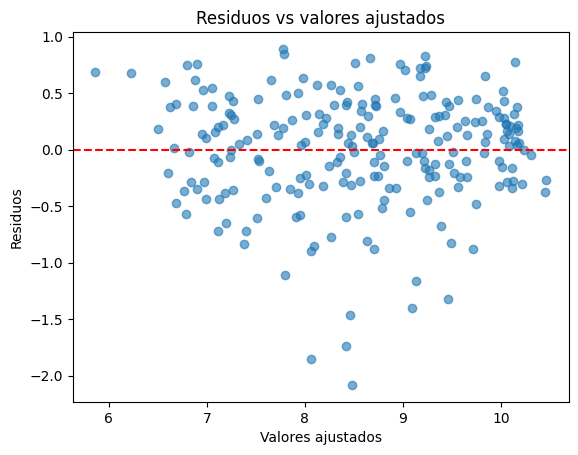

In [108]:
from statsmodels.stats.diagnostic import het_breuschpagan

# Residuos y valores ajustados del modelo
residuals = model.resid
fitted = model.fittedvalues

# Breusch–Pagan test (usa la matriz exógena del modelo: constante + X)
exog = model.model.exog
bp_test = het_breuschpagan(residuals, exog)

# bp_test devuelve: (LM stat, LM p-value, F stat, F p-value)
print("Breusch–Pagan LM p-valor:", bp_test[1])
print("Breusch–Pagan F p-valor:", bp_test[3])

# Gráfico residuos vs valores ajustados
plt.scatter(fitted, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs valores ajustados")
plt.show()

El gráfico de residuos frente a los valores ajustados muestra una dispersión de los errores aproximadamente simétrica alrededor de cero y relativamente constante a lo largo de todo el rango de valores ajustados. No se aprecia una estructura clara en forma de embudo ni un incremento sistemático de la varianza de los residuos a medida que aumentan los valores ajustados, lo que sugiere que la variabilidad de los errores no depende de forma evidente del nivel de la variable dependiente estimada.

Si bien existen algunas observaciones con residuos de mayor magnitud, estas se encuentran distribuidas de forma aislada y no generan un patrón persistente que indique heterocedasticidad severa. Por tanto, desde un punto de vista gráfico, la hipótesis de homocedasticidad resulta razonable.

Este diagnóstico gráfico se ve reforzado por el test de Breusch–Pagan, cuyos p-valores, tanto para el estadístico LM como para el estadístico F, son superiores a los niveles habituales de significación. En consecuencia, no se rechaza la hipótesis nula de homocedasticidad.

En conjunto, se concluye que no existe evidencia estadística de heterocedasticidad relevante en el modelo estimado y que la hipótesis de varianza constante de los errores se cumple de forma adecuada.

---

### G.4. Independencia de los errores

El estadístico Durbin-Watson mide la autocorrelación de primer orden en los residuos.
- Valores cercanos a 2 indican ausencia de autocorrelación (errores independientes).
- Valores cercanos a 0 indican autocorrelación positiva.
- Valores cercanos a 4 indican autocorrelación negativa.

In [109]:
dw_stat = durbin_watson(residuals)
print('Durbin-Watson:', dw_stat)

Durbin-Watson: 1.8832476833003884


El estadístico de Durbin–Watson obtenido es aproximadamente 1.88, un valor cercano a 2. Esto indica la ausencia de autocorrelación de primer orden en los residuos del modelo.

Dado que valores próximos a 2 se asocian con errores independientes, no existe evidencia de autocorrelación positiva ni negativa relevante. Por tanto, se considera que la hipótesis de independencia de los errores se cumple de forma adecuada en el modelo estimado.

---

### G.5. Normalidad de los residuos

Se verifica la normalidad de los residuos usando el test de Shapiro-Wilk, Anderson-Darling y gráficos de residuos y Q-Q plot.
- Hipótesis nula: Los residuos siguen una distribución normal.
- Hipótesis alternativa: Los residuos no siguen una distribución normal.

#### G.5.1. Shapiro-Wilk

In [110]:
from scipy import stats
from scipy.stats import shapiro, anderson
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Residuos del modelo
residuals = model.resid

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print("Shapiro–Wilk statistic:", shapiro_stat)
print("Shapiro–Wilk p-value:", shapiro_p)

Shapiro–Wilk statistic: 0.9435378659586986
Shapiro–Wilk p-value: 1.1072989132608752e-07


El estadístico obtenido es 0.944 y el p-valor asociado es prácticamente nulo, lo que conduce al rechazo de la hipótesis de normalidad a niveles habituales de significación.

Este resultado indica la presencia de desviaciones respecto a la normalidad. No obstante, conviene tener en cuenta que el test de Shapiro–Wilk es especialmente sensible en muestras de tamaño moderado o grande, de modo que incluso pequeñas desviaciones en las colas de la distribución pueden dar lugar al rechazo de la hipótesis nula. Por tanto, el resultado debe interpretarse conjuntamente con el análisis gráfico de los residuos.


#### G.5.2. Anderson-Darling

In [111]:
result_ad = anderson(residuals, dist='norm')
print(f'Anderson-Darling stat={result_ad.statistic:.4f}')
for i in range(len(result_ad.critical_values)):
    sl, cv = result_ad.significance_level[i], result_ad.critical_values[i]
    print(f'Nivel {sl}%: valor crítico={cv:.4f}')

Anderson-Darling stat=2.1022
Nivel 15.0%: valor crítico=0.5590
Nivel 10.0%: valor crítico=0.6290
Nivel 5.0%: valor crítico=0.7490
Nivel 2.5%: valor crítico=0.8700
Nivel 1.0%: valor crítico=1.0320


C:\Users\dmoya\AppData\Local\Temp\ipykernel_53536\1460969990.py:1: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  result_ad = anderson(residuals, dist='norm')


El test de Anderson–Darling evalúa la normalidad de los residuos poniendo un énfasis especial en el comportamiento de las colas de la distribución. El estadístico obtenido es 2.10, claramente superior a los valores críticos correspondientes incluso al nivel de significación del 1%, lo que implica el rechazo de la hipótesis nula de normalidad.

Este resultado confirma la existencia de desviaciones respecto a la distribución normal, particularmente en las colas, lo cual es coherente con la naturaleza de los datos analizados. En contextos socioeconómicos es habitual observar colas más pesadas o asimetrías moderadas, por lo que el rechazo del test no resulta inesperado ni implica necesariamente una mala especificación del modelo.

#### G.5.3. Histograma y Q-Q plot

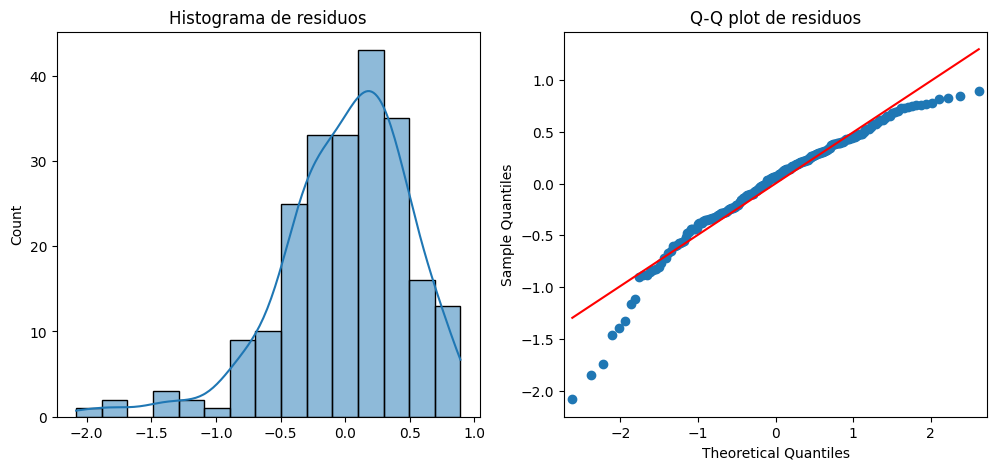

In [112]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.histplot(residuals, kde=True)
plt.title('Histograma de residuos')
plt.subplot(1,2,2)
sm.qqplot(residuals, line='s', ax=plt.gca())
plt.title('Q-Q plot de residuos')
plt.show()

El histograma de los residuos muestra una distribución aproximadamente simétrica alrededor de cero, aunque con una ligera asimetría y una mayor concentración de observaciones en las colas respecto a una normal teórica. Este comportamiento sugiere que la normalidad no se cumple de forma estricta, pero sí de manera razonable en la parte central de la distribución.

El gráfico Q–Q refuerza esta conclusión: los residuos se alinean adecuadamente con la recta teórica en los cuantiles centrales, mientras que se observan desviaciones más acusadas en los extremos, especialmente en la cola izquierda. Estas discrepancias indican colas más pesadas de lo esperado bajo normalidad, pero no un incumplimiento grave que afecte de forma sustancial a la estimación de los coeficientes.

---

## H. (0.5) Evalúa el modelo.

### H.1 Criterios de evaluación del modelo

La evaluación del modelo se realiza atendiendo tanto a criterios cuantitativos de ajuste como a consideraciones cualitativas relacionadas con la interpretabilidad y coherencia económica del modelo. Dado que el objetivo principal es explicar la variabilidad de la variable dependiente mediante un conjunto reducido de variables explicativas, se emplean métricas que permiten valorar el compromiso entre capacidad explicativa y complejidad del modelo.

En primer lugar, se utiliza el coeficiente de determinación ajustado (**R² ajustado**), que mide la proporción de variabilidad explicada por el modelo penalizando la inclusión de variables adicionales. A diferencia del R² clásico, esta medida evita favorecer de forma automática modelos más complejos y resulta especialmente adecuada para comparar modelos con distinto número de regresores.

Adicionalmente, se consideran los criterios de información **AIC** (Akaike Information Criterion) y **BIC** (Bayesian Information Criterion), que evalúan la calidad global del modelo incorporando una penalización explícita por el número de parámetros estimados. Ambos criterios permiten comparar modelos no anidados y favorecen especificaciones más parsimoniosas cuando el incremento en el ajuste no compensa el aumento de complejidad. En particular, el BIC introduce una penalización más severa, lo que resulta útil para identificar modelos excesivamente sobreajustados.

Junto a estos criterios cuantitativos, se tiene en cuenta la **relevancia y la interpretabilidad de las variables incluidas en el modelo**. Se valora positivamente que los coeficientes estimados presenten signos coherentes con la teoría económica y que las variables explicativas representen mecanismos económicos plausibles, evitando especificaciones que, aun mejorando marginalmente las métricas de ajuste, resulten difíciles de interpretar o dependan en exceso de observaciones atípicas.

---

### H.2. Comparación de modelos alternativos

#### H.2.1. Comparación de modelos alternativos según las observaciones influyentes

Con el objetivo de evaluar la robustez del modelo estimado y analizar el impacto de las observaciones influyentes sobre la calidad del ajuste, se comparan distintas especificaciones del modelo que difieren en el tratamiento de dichas observaciones. En particular, se considera el **modelo estimado con la muestra completa**, un **modelo en el que se eliminan las tres observaciones con mayor influencia** según la distancia de Cook y un **modelo en el que se excluyen todas las observaciones identificadas como influyentes**.

Para cada especificación se estiman los parámetros mediante mínimos cuadrados ordinarios y se calculan medidas globales de evaluación, incluyendo el número de observaciones, el coeficiente de determinación ajustado y los criterios de información AIC y BIC. Esta comparación permite valorar el compromiso entre mejora del ajuste, complejidad del modelo y pérdida de información asociada a la eliminación de observaciones, proporcionando una base objetiva para la selección del modelo final.

In [113]:
# H.2 Comparación de modelos: tabla resumen (R2_adj, AIC, BIC, N) para varios modelos

def fit_model_drop_indices(model_base, y, X_sm, drop_idx=None):
    """
    Ajusta un modelo OLS usando y y X_sm (con constante) eliminando índices drop_idx.
    Devuelve el modelo ajustado.
    """
    if drop_idx is None or len(drop_idx) == 0:
        return sm.OLS(y, X_sm).fit()
    drop_idx = list(drop_idx)
    y_r = y.drop(index=drop_idx)
    X_r = X_sm.drop(index=drop_idx)
    return sm.OLS(y_r, X_r).fit()

# --- Asegurar que cooks_d e influential existen ---
influence = model.get_influence()
cooks_d = influence.cooks_distance[0]

n = len(cooks_d)
cooks_threshold = 4 / n
influential = np.where(cooks_d > cooks_threshold)[0]

# Top 3 observaciones más influyentes (por Cook)
top3 = np.argsort(cooks_d)[-3:][::-1]

# Ajustar los tres modelos
model_full = model  # ya ajustado con toda la muestra
model_no_top3 = fit_model_drop_indices(model, y, X_sm, drop_idx=top3)
model_no_influential = fit_model_drop_indices(model, y, X_sm, drop_idx=influential)

# Construir tabla comparativa
def model_metrics(m, name):
    return {
        "Modelo": name,
        "N obs": int(m.nobs),
        "R2": float(m.rsquared),
        "R2_adj": float(m.rsquared_adj),
        "AIC": float(m.aic),
        "BIC": float(m.bic),
    }

comparison_df = pd.DataFrame([
    model_metrics(model_full, "Completo"),
    model_metrics(model_no_top3, "Sin top 3 influyentes"),
    model_metrics(model_no_influential, "Sin influyentes (Cook > 4/n)"),
])

# Redondear para presentación
comparison_df_round = comparison_df.copy()
for col in ["R2", "R2_adj", "AIC", "BIC"]:
    comparison_df_round[col] = comparison_df_round[col].round(3)

comparison_df_round


,Modelo,N obs,R2,R2_adj,AIC,BIC
0,Completo,226,0.828,0.824,337.488,361.432
1,Sin top 3 influyentes,223,0.858,0.854,283.995,307.845
2,Sin influyentes (Cook > 4/n),209,0.870,0.867,235.682,259.079


La tabla comparativa muestra diferencias relevantes entre las distintas especificaciones del modelo en función del tratamiento de las observaciones influyentes. El modelo estimado con la muestra completa presenta un R² ajustado de 0.824, lo que indica una elevada capacidad explicativa, aunque acompañado de valores relativamente altos de los criterios de información AIC y BIC.

Al eliminar las tres observaciones más influyentes según la distancia de Cook, se observa una mejora notable en todas las métricas de evaluación. En particular, el R² ajustado aumenta hasta 0.854, mientras que tanto el AIC como el BIC disminuyen de forma significativa. Este resultado sugiere que un **pequeño número de observaciones con alta influencia condiciona el ajuste global del modelo**.

La exclusión de todas las observaciones identificadas como influyentes produce una mejora adicional en las métricas de ajuste, alcanzando un R² ajustado de 0.867 y los valores más bajos de AIC y BIC entre los modelos considerados. Sin embargo, esta especificación implica una reducción más sustancial del tamaño muestral, pasando de 226 a 209 observaciones, lo que supone una pérdida apreciable de información.

En conjunto, los resultados muestran que la mejora del ajuste al eliminar observaciones influyentes es clara desde un punto de vista cuantitativo. No obstante, dicha mejora debe ponderarse frente al coste asociado a la eliminación de observaciones que representan realidades económicas extremas pero relevantes, así como frente al objetivo de mantener una muestra lo más representativa posible del fenómeno analizado.


##### H.2.1.2. Conclusiones y selección del modelo final

A partir de la comparación realizada, se observa que la **eliminación de observaciones influyentes** conduce a una **mejora sustancial de las métricas de ajuste del modelo**, reflejada en un aumento del R² ajustado y una reducción de los criterios de información AIC y BIC. **No obstante**, estas mejoras vienen acompañadas de una **reducción del tamaño muestral y de la exclusión de observaciones que representan realidades económicas extremas pero reales**.

Dado que las observaciones identificadas como influyentes no corresponden a errores de medición ni a datos inconsistentes, sino a países con características socioeconómicas singulares que forman parte del fenómeno objeto de estudio, su **eliminación implicaría una pérdida de heterogeneidad relevante en la muestra**. Además, el análisis previo ha mostrado que la exclusión de dichas observaciones no altera de forma sustancial los signos, la significancia ni la interpretación económica de los coeficientes estimados.

En consecuencia, se selecciona como modelo final el estimado utilizando la muestra completa. Esta especificación, si bien presenta métricas de ajuste ligeramente inferiores, ofrece una representación más fiel y general del conjunto de datos, preserva la diversidad económica de la muestra y permite una interpretación robusta de los resultados desde un punto de vista econométrico y sustantivo.


#### H.2.2. Comparación adicional: efecto de las transformaciones logarítmicas en las variables explicativas

Como análisis complementario, se compara el modelo final con una especificación alternativa que mantiene la misma variable dependiente (`log_GDP`), pero utiliza las variables explicativas en escala original (sin transformaciones logarítmicas). Esta comparación permite evaluar si las transformaciones aplicadas a las variables explicativas aportan mejoras en términos de ajuste global (R² ajustado) y criterios penalizados (AIC/BIC), y si contribuyen a una especificación más adecuada para el modelo lineal.

In [114]:

# Modelo A (final): con logs en X (ya lo tienes)
model_A = model  # log_GDP ~ log_Infant_mortality + log_Phones + ...

# Modelo B: mismas variables pero SIN logs en X (manteniendo y = log_GDP)
features_no_logs = [
    "Infant.mortality",
    "Phones",
    "Net.migration",
    "Agriculture",
    "Deathrate",
    "Crops"
]

X_B = data_gdp_imp[features_no_logs]
X_B_sm = sm.add_constant(X_B)
model_B = sm.OLS(y, X_B_sm).fit()

# Tabla comparativa
comparison_logs = pd.DataFrame([
    {"Modelo": "A (con logs en X)", "N obs": int(model_A.nobs), "R2_adj": model_A.rsquared_adj, "AIC": model_A.aic, "BIC": model_A.bic},
    {"Modelo": "B (sin logs en X)", "N obs": int(model_B.nobs), "R2_adj": model_B.rsquared_adj, "AIC": model_B.aic, "BIC": model_B.bic},
])

comparison_logs[["R2_adj","AIC","BIC"]] = comparison_logs[["R2_adj","AIC","BIC"]].round(3)
comparison_logs


,Modelo,N obs,R2_adj,AIC,BIC
0,A (con logs en X),226,0.824,337.488,361.432
1,B (sin logs en X),226,0.813,351.163,375.107


##### H.2.2.2. Conclusiones y selección del modelo final

La comparación entre el modelo final, que incorpora transformaciones logarítmicas en algunas variables explicativas, y una especificación alternativa que utiliza dichas variables en escala original muestra diferencias claras en términos de ajuste y calidad del modelo. Manteniendo constante la variable dependiente (`log_GDP`) y el tamaño muestral, el modelo con transformaciones logarítmicas presenta un mayor R² ajustado, lo que indica una mejor capacidad explicativa una vez penalizada la complejidad.

Asimismo, los criterios de información AIC y BIC son sensiblemente inferiores en el modelo con transformaciones logarítmicas, lo que sugiere que esta especificación ofrece un mejor compromiso entre ajuste y parsimonia. Por el contrario, el modelo sin transformaciones presenta valores más elevados de AIC y BIC, indicando una peor adecuación global pese a utilizar el mismo número de variables.

Estos resultados confirman que las transformaciones logarítmicas aplicadas a las variables explicativas contribuyen a mejorar la especificación del modelo, probablemente al capturar relaciones no lineales y reducir la influencia de valores extremos. Además, dichas transformaciones facilitan una interpretación económica más clara de los coeficientes en términos aproximados de elasticidades. En consecuencia, esta comparación refuerza la elección del modelo final como la especificación más adecuada.


## I.(1) Ecuación del modelo final

El modelo final seleccionado se especifica de la siguiente forma:

$$
\log(GDP_i) = \beta_0 
+ \beta_1 \log(\text{Infant mortality}_i)
+ \beta_2 \log(\text{Phones}_i)
+ \beta_3 \text{Net migration}_i
+ \beta_4 \text{Agriculture}_i
+ \beta_5 \text{Deathrate}_i
+ \beta_6 \text{Crops}_i
+ \varepsilon_i
$$

donde \varepsilon_i representa el término de error aleatorio.

### I.1 Interpretación de los coeficientes del modelo final

El coeficiente asociado a `log_Infant_mortality` es **negativo y estadísticamente significativo**, lo que indica que una **mayor mortalidad infantil se asocia con menores niveles de renta per cápita**. Dado que tanto la variable dependiente como esta variable explicativa están en logaritmos, el coeficiente puede interpretarse como una **elasticidad**: un aumento del 1% en la mortalidad infantil se asocia, en promedio, con una disminución porcentual del PIB per cápita, manteniendo constantes el resto de factores.

El coeficiente de `log_Phones` es **positivo y significativo**, lo que sugiere que un **mayor nivel de acceso a infraestructuras de comunicación se relaciona con un mayor nivel de renta**. En este caso, el coeficiente también representa una elasticidad, de modo que un incremento del 1% en el número de teléfonos se asocia con un aumento porcentual del PIB per cápita.

La variable `Net.migration` presenta un coeficiente **positivo**, lo que indica que los países con flujos migratorios netos positivos tienden a mostrar mayores niveles de renta per cápita. Dado que la variable dependiente está en logaritmos y la explicativa en niveles, el coeficiente se interpreta como el **cambio porcentual aproximado en el PIB per cápita asociado a un incremento unitario en la migración neta**, manteniendo constantes el resto de variables.

El coeficiente de `Agriculture` es **negativo** y estadísticamente significativo, lo que sugiere que una **mayor proporción del sector agrícola en la estructura productiva se asocia con menores niveles de renta per cápita**. Este resultado es coherente con la idea de que las economías más dependientes del sector primario tienden a presentar un menor grado de desarrollo económico.

Aunque a priori podría esperarse una relación negativa entre la tasa de mortalidad total y el nivel de renta, los resultados muestran un coeficiente **positivo** y relativamente estable para la variable `Deathrate`. Este resultado persiste incluso al excluir la mortalidad infantil del modelo, lo que indica que el signo positivo no es consecuencia de colinealidad con dicha variable.

No obstante, esta variable puede no medir directamente condiciones sanitarias adversas, sino que podría reflejar la tasa bruta de mortalidad de la población, la cual depende en gran medida de la estructura demográfica de los países.

El hecho de que el signo del coeficiente se mantenga positivo bajo distintas especificaciones del modelo sugiere que `Deathrate` está capturando diferencias estructurales entre países que no se explican únicamente por el nivel de desarrollo económico. En este contexto, el coeficiente no debe interpretarse como un efecto causal directo, sino como una relación condicionada asociada a características demográficas y poblacionales.Por tanto, el coeficiente positivo de `Deathrate` debe interpretarse como un efecto de composición demográfica y no como una relación causal directa entre mortalidad y desarrollo económico.

Con el fin de evaluar la relevancia de la variable `Deathrate`, se estimó una especificación alternativa del modelo excluyéndola del conjunto de regresores. La comparación entre ambas especificaciones muestra que la eliminación de `Deathrate` conlleva una reducción del R² ajustado y un empeoramiento de los criterios de información AIC y BIC, lo que indica una pérdida de calidad global del modelo.
Dado que la inclusión de `Deathrate` mejora el ajuste sin introducir problemas econométricos adicionales, y que su efecto resulta estable entre distintas especificaciones, se decide mantener esta variable en el modelo final. No obstante, su coeficiente se interpreta de forma cautelosa, atendiendo a su carácter condicionado y a la naturaleza agregada de la variable.

Por último, el coeficiente asociado a `Crops` es **negativo y significativo**, indicando que una **mayor proporción de tierra dedicada a cultivos se asocia con menores niveles de renta per cápita**, lo que refuerza la interpretación de que una estructura productiva más orientada al sector primario está relacionada con niveles de desarrollo económico más bajos.

---

## J. (0.75) ¿Qué recomendarías a un país que quiera aumentar su Producto Interior Bruto (GDP)?

Dado que el análisis se ha realizado sobre el PIB per cápita, las recomendaciones que se presentan a continuación deben interpretarse como orientadas a mejorar el nivel medio de renta de la población.

### J.1 Principales factores asociados al GDP per cápita

Los resultados del modelo final muestran que el PIB per cápita está positivamente asociado con el acceso a infraestructuras de comunicación (`log_Phones`) y con flujos migratorios netos positivos (`Net.migration`). Por el contrario, se observa una relación negativa entre el nivel de renta y la mortalidad infantil, así como con una mayor dependencia del sector primario, medida a través del peso de la agricultura y de los cultivos en la estructura productiva.

Estos resultados sugieren que los países con mejores infraestructuras, mayor capital humano y una estructura económica más diversificada tienden a presentar niveles de renta per cápita más elevados.

---

### J.2 Recomendaciones derivadas del modelo

En primer lugar, el efecto positivo del número de teléfonos per cápita sugiere que el fortalecimiento de las infraestructuras de comunicación y conectividad puede estar asociado con mayores niveles de renta. En este sentido, políticas orientadas a mejorar el acceso a tecnologías de la información y la comunicación podrían contribuir al desarrollo económico, facilitando la integración de los mercados, el acceso a la información y el aumento de la productividad.

En segundo lugar, la relación negativa entre la mortalidad infantil y el PIB per cápita pone de manifiesto la importancia de las políticas de salud pública, especialmente aquellas dirigidas a la infancia. La inversión en sistemas sanitarios básicos, nutrición y acceso a servicios médicos puede tener efectos positivos a largo plazo sobre el desarrollo económico.

Asimismo, el peso negativo del sector agrícola y de los cultivos en el PIB sugiere que una elevada dependencia del sector primario está asociada con menores niveles de renta per cápita. En consecuencia, políticas orientadas a la diversificación productiva, al desarrollo del sector industrial y de servicios, y al aumento del valor añadido de la producción agrícola podrían favorecer un crecimiento económico más sostenido.

Por último, el coeficiente positivo de la migración neta indica que los países con capacidad para atraer población pueden beneficiarse de un mayor dinamismo económico. En este contexto, políticas que favorezcan la integración de migrantes y la atracción de capital humano podrían contribuir a elevar el nivel de renta per cápita.

---

### J.3 Limitaciones de las recomendaciones

Debe señalarse que las recomendaciones anteriores se basan en un análisis observacional y transversal, por lo que no permiten establecer relaciones de causalidad directa. Además, algunas variables del modelo, como la tasa de mortalidad total, pueden estar capturando efectos estructurales o demográficos difíciles de interpretar de forma aislada.

Por tanto, las recomendaciones deben entenderse como orientaciones generales basadas en asociaciones empíricas y no como prescripciones de política económica definitivas. Cualquier estrategia de desarrollo debería complementarse con análisis adicionales que tengan en cuenta el contexto institucional, social y económico específico de cada país.